<a href="https://colab.research.google.com/github/papoochu/student-ai-learning-analysis/blob/main/notebooks/zero_shot_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Step 1: Install libraries for zero-shot classification

!pip -q install transformers torch accelerate scikit-learn pandas matplotlib seaborn

import torch
import transformers
import sklearn
import pandas as pd

print("Setup complete!")
print("PyTorch version:", torch.__version__)
print("Transformers version:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")


Setup complete!
PyTorch version: 2.14.1+cu130
Transformers version: 5.22.1
GPU available: True
GPU: Tesla T4


In [4]:

# Step 2: Load human-reviewed annotations and codebook

import pandas as pd

base_url = (
    "https://raw.githubusercontent.com/"
    "papoochu/student-ai-learning-analysis/main/"
    "results/"
)

annotations = pd.read_csv(
    base_url + "studychat_annotation_200_reviewed.csv"
)

codebook = pd.read_csv(
    base_url + "studychat_assistance_codebook_final.csv"
)

coding_rules = pd.read_csv(
    base_url + "studychat_coding_rules_final.csv"
)

print("Annotations loaded:", len(annotations))
print("Codebook categories:", len(codebook))
print("Coding rules:", len(coding_rules))

print("\nAnnotation columns:")
print(annotations.columns.tolist())

print("\nHuman label distribution:")
print(annotations["human_label"].value_counts(dropna=False))

print("\nMissing human labels:")
print(annotations["human_label"].isna().sum())

display(
    annotations[
        ["sample_id", "prompt", "human_label"]
    ].head(5)
)


Annotations loaded: 200
Codebook categories: 8
Coding rules: 11

Annotation columns:
['sample_id', 'userId', 'chatId', 'prompt', 'human_label', 'ambiguous', 'notes', 'review_status']

Human label distribution:
human_label
Code Generation              45
Code Explanation / Review    33
Data Processing              29
Concept Explanation          24
Other / Unclear              22
Problem Solving              22
Debugging                    14
Assignment Guidance          11
Name: count, dtype: int64

Missing human labels:
0


,sample_id,prompt,human_label
0,P001,how should I tokenize my data before running c...,Data Processing
1,P002,Is this correct for the following spec:\n\nTo ...,Code Explanation / Review
2,P003,I have a main.py with this in it\n\nfrom autoc...,Code Explanation / Review
3,P004,I have this function and code:\ndef train_mode...,Code Explanation / Review
4,P005,how to get percentages of each class in a pred...,Concept Explanation


In [5]:

# Step 3: Load and test the BART zero-shot classifier

import torch
from transformers import pipeline

model_name = "facebook/bart-large-mnli"

classifier = pipeline(
    task="zero-shot-classification",
    model=model_name,
    device=0 if torch.cuda.is_available() else -1
)

candidate_labels = codebook["Label"].tolist()

print("Model loaded:", model_name)
print("Device:", classifier.device)
print("Candidate labels:", candidate_labels)

# First test: only five prompts
test_prompts = annotations["prompt"].head(5).astype(str).tolist()

test_results = classifier(
    test_prompts,
    candidate_labels=candidate_labels,
    hypothesis_template="This student is requesting {}.",
    multi_label=False,
    truncation=True,
    batch_size=4
)

for i, result in enumerate(test_results):
    print(f"\nPrompt {annotations.iloc[i]['sample_id']}:")
    print("Human label:", annotations.iloc[i]["human_label"])
    print("Predicted label:", result["labels"][0])
    print("Confidence:", round(result["scores"][0], 3))


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Model loaded: facebook/bart-large-mnli
Device: cuda:0
Candidate labels: ['Concept Explanation', 'Debugging', 'Code Generation', 'Code Explanation / Review', 'Problem Solving', 'Data Processing', 'Assignment Guidance', 'Other / Unclear']

Prompt P001:
Human label: Data Processing
Predicted label: Assignment Guidance
Confidence: 0.284

Prompt P002:
Human label: Code Explanation / Review
Predicted label: Code Explanation / Review
Confidence: 0.262

Prompt P003:
Human label: Code Explanation / Review
Predicted label: Other / Unclear
Confidence: 0.325

Prompt P004:
Human label: Code Explanation / Review
Predicted label: Code Explanation / Review
Confidence: 0.208

Prompt P005:
Human label: Concept Explanation
Predicted label: Data Processing
Confidence: 0.501


In [6]:

# Step 4: Classify all 200 reviewed prompts

import pandas as pd
import numpy as np
import time

prompts = annotations["prompt"].fillna("").astype(str).tolist()

start_time = time.time()

results = classifier(
    prompts,
    candidate_labels=candidate_labels,
    hypothesis_template="This student is requesting {}.",
    multi_label=False,
    truncation=True,
    batch_size=4
)

# Store the top prediction and its score
annotations["zero_shot_label"] = [
    result["labels"][0] for result in results
]

annotations["zero_shot_score"] = [
    result["scores"][0] for result in results
]

# Store the scores for all eight categories
for label in candidate_labels:
    annotations[f"score_{label}"] = [
        result["scores"][result["labels"].index(label)]
        for result in results
    ]

elapsed = time.time() - start_time

print(f"Classified {len(annotations)} prompts")
print(f"Elapsed time: {elapsed:.1f} seconds")
print(
    "Predictions matching human labels:",
    (
        annotations["zero_shot_label"]
        == annotations["human_label"]
    ).sum()
)

display(
    annotations[
        [
            "sample_id",
            "human_label",
            "zero_shot_label",
            "zero_shot_score"
        ]
    ].head(10)
)

# Save predictions so they aren't lost if Colab disconnects
annotations.to_csv(
    "studychat_zero_shot_200_predictions.csv",
    index=False
)

print("Predictions saved to studychat_zero_shot_200_predictions.csv")


Classified 200 prompts
Elapsed time: 75.3 seconds
Predictions matching human labels: 61


,sample_id,human_label,zero_shot_label,zero_shot_score
0,P001,Data Processing,Assignment Guidance,0.284078
1,P002,Code Explanation / Review,Code Explanation / Review,0.261934
2,P003,Code Explanation / Review,Other / Unclear,0.325197
3,P004,Code Explanation / Review,Code Explanation / Review,0.208382
4,P005,Concept Explanation,Data Processing,0.500839
5,P006,Code Explanation / Review,Code Explanation / Review,0.363327
6,P007,Debugging,Other / Unclear,0.514510
7,P008,Data Processing,Other / Unclear,0.179130
8,P009,Code Generation,Code Explanation / Review,0.205623
9,P010,Problem Solving,Other / Unclear,0.293996


Predictions saved to studychat_zero_shot_200_predictions.csv


In [7]:

# Step 5: Evaluate zero-shot classification performance

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score,
    classification_report
)

y_true = annotations["human_label"]
y_pred = annotations["zero_shot_label"]

labels = codebook["Label"].tolist()

accuracy = accuracy_score(y_true, y_pred)
macro_precision = precision_score(
    y_true, y_pred, labels=labels,
    average="macro", zero_division=0
)
macro_recall = recall_score(
    y_true, y_pred, labels=labels,
    average="macro", zero_division=0
)
macro_f1 = f1_score(
    y_true, y_pred, labels=labels,
    average="macro", zero_division=0
)
weighted_f1 = f1_score(
    y_true, y_pred, labels=labels,
    average="weighted", zero_division=0
)
kappa = cohen_kappa_score(
    y_true, y_pred, labels=labels
)

summary = pd.DataFrame([{
    "Accuracy": accuracy,
    "Macro Precision": macro_precision,
    "Macro Recall": macro_recall,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1,
    "Cohen's Kappa": kappa
}])

print("ZERO-SHOT CLASSIFICATION RESULTS")
display(summary.round(4))

print("\nPER-CATEGORY CLASSIFICATION REPORT")
print(
    classification_report(
        y_true,
        y_pred,
        labels=labels,
        zero_division=0
    )
)

# Save evaluation summary
summary.to_csv(
    "studychat_zero_shot_evaluation.csv",
    index=False
)


ZERO-SHOT CLASSIFICATION RESULTS


,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1,Cohen's Kappa
0,0.305,0.2905,0.3167,0.2497,0.2535,0.2074



PER-CATEGORY CLASSIFICATION REPORT
                           precision    recall  f1-score   support

      Concept Explanation       0.50      0.50      0.50        24
                Debugging       0.00      0.00      0.00        14
          Code Generation       0.50      0.02      0.04        45
Code Explanation / Review       0.33      0.58      0.42        33
          Problem Solving       0.14      0.05      0.07        22
          Data Processing       0.45      0.34      0.39        29
      Assignment Guidance       0.16      0.45      0.24        11
          Other / Unclear       0.23      0.59      0.33        22

                 accuracy                           0.30       200
                macro avg       0.29      0.32      0.25       200
             weighted avg       0.34      0.30      0.25       200



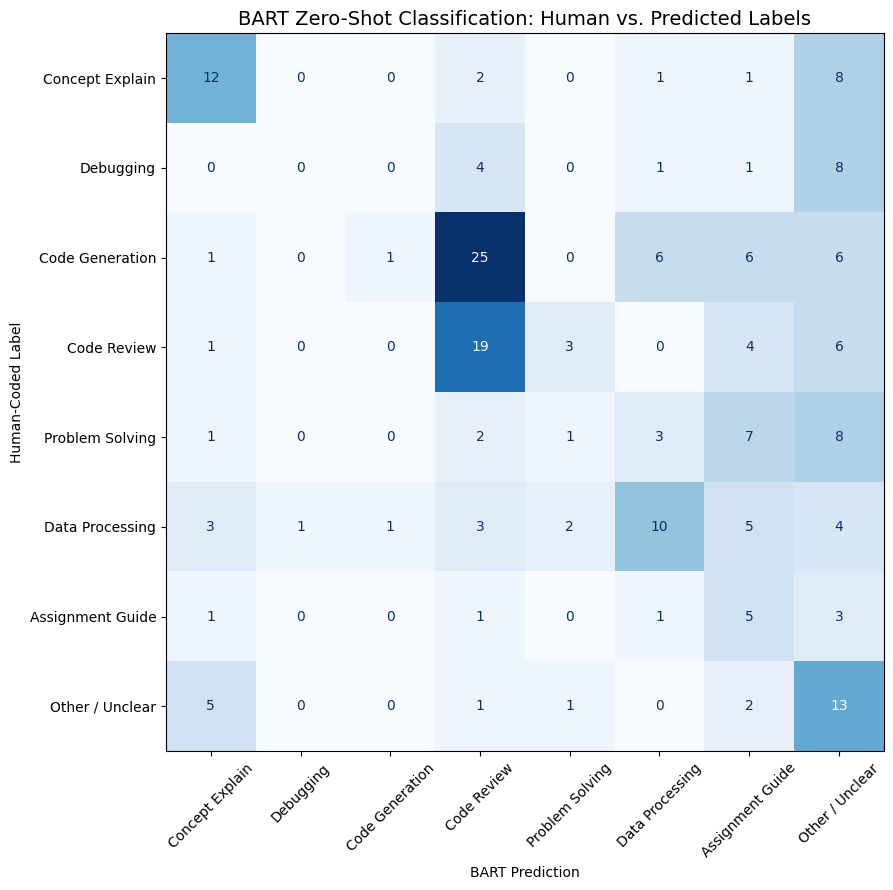

,Concept Explanation,Debugging,Code Generation,Code Explanation / Review,Problem Solving,Data Processing,Assignment Guidance,Other / Unclear
Concept Explanation,12,0,0,2,0,1,1,8
Debugging,0,0,0,4,0,1,1,8
Code Generation,1,0,1,25,0,6,6,6
Code Explanation / Review,1,0,0,19,3,0,4,6
Problem Solving,1,0,0,2,1,3,7,8
Data Processing,3,1,1,3,2,10,5,4
Assignment Guidance,1,0,0,1,0,1,5,3
Other / Unclear,5,0,0,1,1,0,2,13


In [8]:

# Step 6: Confusion matrix for BART zero-shot classification

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

labels = codebook["Label"].tolist()

cm = confusion_matrix(
    annotations["human_label"],
    annotations["zero_shot_label"],
    labels=labels
)

# Readable shortened names for the chart
short_labels = [
    "Concept Explain",
    "Debugging",
    "Code Generation",
    "Code Review",
    "Problem Solving",
    "Data Processing",
    "Assignment Guide",
    "Other / Unclear"
]

fig, ax = plt.subplots(figsize=(11, 9))

display_cm = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=short_labels
)

display_cm.plot(
    ax=ax,
    cmap="Blues",
    values_format="d",
    colorbar=False,
    xticks_rotation=45
)

ax.set_title(
    "BART Zero-Shot Classification: Human vs. Predicted Labels",
    fontsize=14
)

ax.set_xlabel("BART Prediction")
ax.set_ylabel("Human-Coded Label")

plt.tight_layout()
plt.show()

# Show the actual numbers in a table
cm_df = pd.DataFrame(
    cm,
    index=labels,
    columns=labels
)

display(cm_df)


In [9]:

# Step 7: Inspect common zero-shot classification errors

import pandas as pd

error_cases = [
    ("Code Generation", "Code Explanation / Review"),
    ("Debugging", "Other / Unclear"),
    ("Problem Solving", "Other / Unclear"),
    ("Concept Explanation", "Other / Unclear")
]

examples = []

for actual_label, predicted_label in error_cases:

    subset = annotations[
        (annotations["human_label"] == actual_label) &
        (annotations["zero_shot_label"] == predicted_label)
    ]

    # Show the first three examples from each error type
    for _, row in subset.head(3).iterrows():
        examples.append({
            "Sample ID": row["sample_id"],
            "Human Label": actual_label,
            "BART Prediction": predicted_label,
            "BART Score": round(
                row["zero_shot_score"], 3
            ),
            "Prompt": str(row["prompt"])[:350]
        })

error_examples_df = pd.DataFrame(examples)

display(error_examples_df)


,Sample ID,Human Label,BART Prediction,BART Score,Prompt
0,P009,Code Generation,Code Explanation / Review,0.206,### Section 1.3 Tensor Operations\n\nTensor op...
1,P013,Code Generation,Code Explanation / Review,0.324,"**SQL Query**\n```sql\nSELECT Target, COUNT(*)..."
2,P018,Code Generation,Code Explanation / Review,0.205,complete this method:\n\n def build_tree(se...
3,P007,Debugging,Other / Unclear,0.515,there is no isEndOfWord
4,P050,Debugging,Other / Unclear,0.449,it still doesn't work...
5,P057,Debugging,Other / Unclear,0.254,"print(""UCS Suggestions:"", autocomplete_engine...."
6,P010,Problem Solving,Other / Unclear,0.294,How can I have the path cost in each node? Wou...
7,P052,Problem Solving,Other / Unclear,0.602,isn't b there 4 times instead of 2?
8,P091,Problem Solving,Other / Unclear,0.235,Coefficients --> [ 0.00000000e+00 1.20000001e...
9,P014,Concept Explanation,Other / Unclear,0.296,how do u get a substring of a string


In [10]:

# Step 8: Test descriptive zero-shot category labels

import time
import pandas as pd

label_descriptions = {
    "Concept Explanation":
        "an explanation of how or why a concept works",

    "Debugging":
        "help diagnosing or fixing an error or something that is not working",

    "Code Generation":
        "writing, completing, or translating programming code",

    "Code Explanation / Review":
        "explaining, checking, or reviewing existing programming code",

    "Problem Solving":
        "a finished answer to a question, calculation, writing task, or problem",

    "Data Processing":
        "cleaning, formatting, transforming, or analyzing data",

    "Assignment Guidance":
        "clarification of assignment instructions or requirements",

    "Other / Unclear":
        "a request whose intended assistance is unclear"
}

description_to_label = {
    description: label
    for label, description in label_descriptions.items()
}

descriptive_candidates = list(description_to_label.keys())

start_time = time.time()

descriptive_results = classifier(
    annotations["prompt"].fillna("").astype(str).tolist(),
    candidate_labels=descriptive_candidates,
    hypothesis_template="This student is requesting {}.",
    multi_label=False,
    truncation=True,
    batch_size=4
)

annotations["descriptive_zero_shot_label"] = [
    description_to_label[result["labels"][0]]
    for result in descriptive_results
]

annotations["descriptive_zero_shot_score"] = [
    result["scores"][0]
    for result in descriptive_results
]

print(f"Elapsed time: {time.time() - start_time:.1f} seconds")

print(
    "Correct predictions:",
    (
        annotations["descriptive_zero_shot_label"]
        == annotations["human_label"]
    ).sum(),
    "out of",
    len(annotations)
)

display(
    annotations[
        [
            "sample_id",
            "human_label",
            "zero_shot_label",
            "descriptive_zero_shot_label"
        ]
    ].head(10)
)

annotations.to_csv(
    "studychat_zero_shot_200_comparison.csv",
    index=False
)


Elapsed time: 86.1 seconds
Correct predictions: 61 out of 200


,sample_id,human_label,zero_shot_label,descriptive_zero_shot_label
0,P001,Data Processing,Assignment Guidance,Assignment Guidance
1,P002,Code Explanation / Review,Code Explanation / Review,Assignment Guidance
2,P003,Code Explanation / Review,Other / Unclear,Other / Unclear
3,P004,Code Explanation / Review,Code Explanation / Review,Code Explanation / Review
4,P005,Concept Explanation,Data Processing,Assignment Guidance
5,P006,Code Explanation / Review,Code Explanation / Review,Code Explanation / Review
6,P007,Debugging,Other / Unclear,Other / Unclear
7,P008,Data Processing,Other / Unclear,Other / Unclear
8,P009,Code Generation,Code Explanation / Review,Code Explanation / Review
9,P010,Problem Solving,Other / Unclear,Concept Explanation


In [11]:

# Step 9: Compare short labels vs descriptive labels

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    cohen_kappa_score
)

y_true = annotations["human_label"]
baseline = annotations["zero_shot_label"]
descriptive = annotations["descriptive_zero_shot_label"]

labels = codebook["Label"].tolist()

comparison_results = []

for name, predictions in [
    ("Short category names", baseline),
    ("Descriptive category labels", descriptive)
]:
    comparison_results.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Macro Precision": precision_score(
            y_true, predictions, labels=labels,
            average="macro", zero_division=0
        ),
        "Macro Recall": recall_score(
            y_true, predictions, labels=labels,
            average="macro", zero_division=0
        ),
        "Macro F1": f1_score(
            y_true, predictions, labels=labels,
            average="macro", zero_division=0
        ),
        "Cohen's Kappa": cohen_kappa_score(
            y_true, predictions, labels=labels
        )
    })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

# Check which predictions changed
changed = baseline != descriptive

baseline_correct = baseline == y_true
descriptive_correct = descriptive == y_true

print("\nPredictions that changed:", changed.sum())

print(
    "Baseline correct -> Descriptive incorrect:",
    (baseline_correct & ~descriptive_correct).sum()
)

print(
    "Baseline incorrect -> Descriptive correct:",
    (~baseline_correct & descriptive_correct).sum()
)

print("\nPrediction counts by experiment:")

distribution_df = pd.DataFrame({
    "Baseline": baseline.value_counts(),
    "Descriptive": descriptive.value_counts()
}).fillna(0).astype(int)

display(distribution_df.reindex(labels, fill_value=0))


,Experiment,Accuracy,Macro Precision,Macro Recall,Macro F1,Cohen's Kappa
0,Short category names,0.305,0.2905,0.3167,0.2497,0.2074
1,Descriptive category labels,0.305,0.4555,0.3517,0.2979,0.2139



Predictions that changed: 117
Baseline correct -> Descriptive incorrect: 29
Baseline incorrect -> Descriptive correct: 29

Prediction counts by experiment:


,Baseline,Descriptive
Concept Explanation,24,33
Debugging,1,5
Code Generation,2,15
Code Explanation / Review,57,41
Problem Solving,7,6
Data Processing,22,4
Assignment Guidance,31,56
Other / Unclear,56,40


In [12]:

# Step 10: Compare per-category F1 scores

import pandas as pd
from sklearn.metrics import classification_report

labels = codebook["Label"].tolist()

baseline_report = classification_report(
    annotations["human_label"],
    annotations["zero_shot_label"],
    labels=labels,
    output_dict=True,
    zero_division=0
)

descriptive_report = classification_report(
    annotations["human_label"],
    annotations["descriptive_zero_shot_label"],
    labels=labels,
    output_dict=True,
    zero_division=0
)

rows = []

for label in labels:
    baseline_f1 = baseline_report[label]["f1-score"]
    descriptive_f1 = descriptive_report[label]["f1-score"]

    rows.append({
        "Category": label,
        "Human Samples": baseline_report[label]["support"],
        "Baseline F1": baseline_f1,
        "Descriptive F1": descriptive_f1,
        "F1 Change": descriptive_f1 - baseline_f1,
        "Descriptive Recall": descriptive_report[label]["recall"]
    })

category_comparison_df = pd.DataFrame(rows)

display(
    category_comparison_df.round(3)
)

category_comparison_df.to_csv(
    "studychat_zero_shot_category_comparison.csv",
    index=False
)


,Category,Human Samples,Baseline F1,Descriptive F1,F1 Change,Descriptive Recall
0,Concept Explanation,24.0,0.500,0.526,0.026,0.625
1,Debugging,14.0,0.000,0.211,0.211,0.143
2,Code Generation,45.0,0.043,0.300,0.257,0.200
3,Code Explanation / Review,33.0,0.422,0.216,-0.206,0.242
4,Problem Solving,22.0,0.069,0.357,0.288,0.227
5,Data Processing,29.0,0.392,0.182,-0.210,0.103
6,Assignment Guidance,11.0,0.238,0.269,0.031,0.818
7,Other / Unclear,22.0,0.333,0.323,-0.011,0.455


In [13]:

# Step 11: Compare zero-shot performance by ambiguity

import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

# Normalize ambiguity flags
annotations["ambiguous_normalized"] = (
    annotations["ambiguous"]
    .fillna("No")
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(["yes", "true", "1", "y"])
)

labels = codebook["Label"].tolist()

rows = []

for ambiguous_value, group_name in [
    (False, "Not flagged ambiguous"),
    (True, "Flagged ambiguous")
]:
    subset = annotations[
        annotations["ambiguous_normalized"] == ambiguous_value
    ]

    for experiment, prediction_col in [
        ("Short labels", "zero_shot_label"),
        ("Descriptive labels", "descriptive_zero_shot_label")
    ]:
        rows.append({
            "Group": group_name,
            "Experiment": experiment,
            "Prompts": len(subset),
            "Accuracy": accuracy_score(
                subset["human_label"],
                subset[prediction_col]
            ),
            "Macro F1": f1_score(
                subset["human_label"],
                subset[prediction_col],
                labels=labels,
                average="macro",
                zero_division=0
            )
        })

ambiguity_results_df = pd.DataFrame(rows)

display(ambiguity_results_df.round(4))

ambiguity_results_df.to_csv(
    "studychat_zero_shot_ambiguity_results.csv",
    index=False
)


,Group,Experiment,Prompts,Accuracy,Macro F1
0,Not flagged ambiguous,Short labels,113,0.3451,0.2795
1,Not flagged ambiguous,Descriptive labels,113,0.3097,0.2875
2,Flagged ambiguous,Short labels,87,0.2529,0.1840
3,Flagged ambiguous,Descriptive labels,87,0.2989,0.2851


In [14]:

# Step 13: Create development and held-out test sets

import pandas as pd
from sklearn.model_selection import train_test_split

development_df, test_df = train_test_split(
    annotations,
    test_size=0.5,
    random_state=42,
    stratify=annotations["human_label"]
)

development_df = development_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Development prompts:", len(development_df))
print("Test prompts:", len(test_df))

print("\nCategory distribution:")
distribution = pd.DataFrame({
    "Development": development_df["human_label"].value_counts(),
    "Test": test_df["human_label"].value_counts()
}).fillna(0).astype(int)

display(distribution)

print("\nOverlap in sample IDs:",
      len(
          set(development_df["sample_id"])
          & set(test_df["sample_id"])
      ))


Development prompts: 100
Test prompts: 100

Category distribution:


,Development,Test
human_label,,
Code Generation,22,23
Code Explanation / Review,17,16
Data Processing,14,15
Concept Explanation,12,12
Other / Unclear,11,11
Problem Solving,11,11
Debugging,7,7
Assignment Guidance,6,5



Overlap in sample IDs: 0


In [15]:

# Step 14: Test action-focused category descriptions
# Development set only — do not tune against the test set

import time
import pandas as pd

action_descriptions = {
    "Concept Explanation":
        "an explanation of a concept or how something works",

    "Debugging":
        "help finding or fixing an error, bug, or code that does not work",

    "Code Generation":
        "new programming code, completing TODO sections, "
        "implementing functions, or translating SQL into Pandas code",

    "Code Explanation / Review":
        "an explanation, correctness check, or review of existing code",

    "Problem Solving":
        "a completed answer to a math, logic, writing, or other question",

    "Data Processing":
        "cleaned, formatted, transformed, or analyzed data as the result",

    "Assignment Guidance":
        "clarification about assignment instructions or requirements",

    "Other / Unclear":
        "help with a request whose intended action cannot be determined"
}

description_to_label = {
    description: label
    for label, description in action_descriptions.items()
}

start = time.time()

development_results = classifier(
    development_df["prompt"].fillna("").astype(str).tolist(),
    candidate_labels=list(description_to_label.keys()),
    hypothesis_template="This student wants {}.",
    multi_label=False,
    truncation=True,
    batch_size=4
)

development_df["action_focused_label"] = [
    description_to_label[result["labels"][0]]
    for result in development_results
]

from sklearn.metrics import accuracy_score, f1_score

y_true = development_df["human_label"]

rows = []

for name, column in [
    ("Short labels", "zero_shot_label"),
    ("Descriptive labels", "descriptive_zero_shot_label"),
    ("Action-focused labels", "action_focused_label")
]:
    rows.append({
        "Experiment": name,
        "Accuracy": accuracy_score(y_true, development_df[column]),
        "Macro F1": f1_score(
            y_true,
            development_df[column],
            labels=codebook["Label"].tolist(),
            average="macro",
            zero_division=0
        ),
        "Code Generation Recall": (
            (
                (development_df["human_label"] == "Code Generation")
                & (development_df[column] == "Code Generation")
            ).sum()
            / (development_df["human_label"] == "Code Generation").sum()
        )
    })

development_comparison_df = pd.DataFrame(rows)

print(f"Classification completed in {time.time() - start:.1f} seconds")
display(development_comparison_df.round(4))

print("\nAction-focused prediction distribution:")
display(development_df["action_focused_label"].value_counts())


Classification completed in 40.9 seconds


,Experiment,Accuracy,Macro F1,Code Generation Recall
0,Short labels,0.32,0.2700,0.0455
1,Descriptive labels,0.31,0.2980,0.1818
2,Action-focused labels,0.29,0.2523,0.1364



Action-focused prediction distribution:


,count
action_focused_label,
Concept Explanation,42
Assignment Guidance,26
Data Processing,10
Other / Unclear,10
Code Explanation / Review,7
Code Generation,3
Debugging,1
Problem Solving,1


In [16]:

# Step 15: Sentence-BERT zero-shot classification
# Evaluate on the development set only

!pip -q install sentence-transformers

import numpy as np
import pandas as pd

from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.metrics import accuracy_score, f1_score

# Load sentence embedding model
embedding_model = SentenceTransformer(
    "sentence-transformers/all-MiniLM-L6-v2",
    device="cuda"
)

# Natural-language descriptions of each category
sbert_descriptions = {
    "Concept Explanation":
        "A student asks for an explanation of a concept, principle, "
        "or how something works.",

    "Debugging":
        "A student asks for help diagnosing or fixing an error, "
        "bug, or something that is not working.",

    "Code Generation":
        "A student asks the AI to write, complete, implement, "
        "or translate programming code, including TODO sections "
        "and SQL-to-Pandas conversions.",

    "Code Explanation / Review":
        "A student asks the AI to explain existing code, "
        "check whether code is correct, or review an implementation.",

    "Problem Solving":
        "A student asks for a finished answer to a math, logic, "
        "writing, logistical, or other question.",

    "Data Processing":
        "A student asks the AI to clean, format, transform, "
        "or analyze data and provide the processed result.",

    "Assignment Guidance":
        "A student asks for clarification about assignment "
        "requirements, instructions, or expectations.",

    "Other / Unclear":
        "A student's message is ambiguous, incomplete, "
        "or does not contain a clear assistance request."
}

sbert_labels = list(sbert_descriptions.keys())

# Embed both prompts and category descriptions
prompt_embeddings = embedding_model.encode(
    development_df["prompt"].fillna("").astype(str).tolist(),
    batch_size=32,
    show_progress_bar=True
)

label_embeddings = embedding_model.encode(
    list(sbert_descriptions.values()),
    batch_size=8
)

# Match each prompt to the most similar description
similarities = cosine_similarity(
    prompt_embeddings,
    label_embeddings
)

predicted_indices = similarities.argmax(axis=1)

development_df["sbert_label"] = [
    sbert_labels[i] for i in predicted_indices
]

development_df["sbert_similarity"] = similarities.max(axis=1)

# Compare against human labels
accuracy = accuracy_score(
    development_df["human_label"],
    development_df["sbert_label"]
)

macro_f1 = f1_score(
    development_df["human_label"],
    development_df["sbert_label"],
    labels=codebook["Label"].tolist(),
    average="macro",
    zero_division=0
)

print("Sentence-BERT accuracy:", round(accuracy, 4))
print("Sentence-BERT macro F1:", round(macro_f1, 4))

print("\nPrediction distribution:")
display(development_df["sbert_label"].value_counts())

display(
    development_df[
        ["sample_id", "human_label", "sbert_label"]
    ].head(10)
)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (7 outputs left out)

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

Sentence-BERT accuracy: 0.28
Sentence-BERT macro F1: 0.2454

Prediction distribution:


,count
sbert_label,
Code Generation,42
Data Processing,25
Other / Unclear,12
Code Explanation / Review,9
Assignment Guidance,4
Concept Explanation,4
Problem Solving,3
Debugging,1


,sample_id,human_label,sbert_label
0,P110,Code Explanation / Review,Code Generation
1,P090,Code Explanation / Review,Data Processing
2,P026,Code Explanation / Review,Code Explanation / Review
3,P074,Code Explanation / Review,Code Generation
4,P040,Concept Explanation,Code Generation
5,P041,Code Explanation / Review,Code Generation
6,P116,Code Generation,Code Generation
7,P170,Code Generation,Code Explanation / Review
8,P072,Other / Unclear,Other / Unclear
9,P057,Debugging,Other / Unclear


In [17]:

# Step 16: Explore action phrases in development prompts

import pandas as pd

action_patterns = {
    "Code completion / TODO": r"\b(?:todo|to do|complete this|fill in|implement)\b",
    "Code writing": r"\b(?:write|create|generate)\s+(?:me\s+)?(?:a\s+|the\s+)?(?:python|code|function|script|program)\b",
    "SQL to Pandas": r"\b(?:convert|translate)\b.*\bsql\b.*\bpandas\b",
    "Debugging": r"\b(?:error|traceback|exception|doesn.t work|not working|fix|debug)\b",
    "Explanation": r"\b(?:explain|what is|what does|why does|how does)\b",
    "Code review": r"\b(?:is this correct|is my code correct|check my code|review my code)\b",
    "Finished answer": r"\b(?:give me the answer|solve this|answer this|write me|calculate)\b"
}

rows = []

for name, pattern in action_patterns.items():

    matches = development_df["prompt"].fillna("").str.contains(
        pattern,
        case=False,
        regex=True
    )

    rows.append({
        "Action Pattern": name,
        "Matching Prompts": int(matches.sum()),
        "Percentage": round(100 * matches.mean(), 1)
    })

pattern_counts_df = pd.DataFrame(rows)

display(
    pattern_counts_df.sort_values(
        "Matching Prompts",
        ascending=False
    )
)


,Action Pattern,Matching Prompts,Percentage
0,Code completion / TODO,17,17.0
4,Explanation,10,10.0
3,Debugging,5,5.0
2,SQL to Pandas,3,3.0
1,Code writing,1,1.0
6,Finished answer,1,1.0
5,Code review,0,0.0


In [18]:

# Step 17: Check action-pattern reliability against human labels
# Development set only

import pandas as pd

expected_categories = {
    "Code completion / TODO": "Code Generation",
    "Code writing": "Code Generation",
    "SQL to Pandas": "Code Generation",
    "Debugging": "Debugging",
    "Explanation": "Concept Explanation",
    "Code review": "Code Explanation / Review",
    "Finished answer": "Problem Solving"
}

rows = []

for pattern_name, regex in action_patterns.items():

    matches = development_df["prompt"].fillna("").str.contains(
        regex,
        case=False,
        regex=True
    )

    matched = development_df.loc[matches]

    target_label = expected_categories[pattern_name]

    correct_matches = (
        matched["human_label"] == target_label
    ).sum()

    precision = (
        correct_matches / len(matched)
        if len(matched) > 0 else None
    )

    rows.append({
        "Pattern": pattern_name,
        "Expected Label": target_label,
        "Matches": len(matched),
        "Correct Matches": correct_matches,
        "Pattern Precision": precision
    })

pattern_precision_df = pd.DataFrame(rows)

display(
    pattern_precision_df.sort_values(
        "Matches",
        ascending=False
    ).round(3)
)


,Pattern,Expected Label,Matches,Correct Matches,Pattern Precision
0,Code completion / TODO,Code Generation,17,9,0.529
4,Explanation,Concept Explanation,10,4,0.400
3,Debugging,Debugging,5,2,0.400
2,SQL to Pandas,Code Generation,3,3,1.000
1,Code writing,Code Generation,1,1,1.000
6,Finished answer,Problem Solving,1,1,1.000
5,Code review,Code Explanation / Review,0,0,NaN


In [19]:

# Step 18: Inspect TODO-related false positives
# Development set only

todo_matches = development_df["prompt"].fillna("").str.contains(
    action_patterns["Code completion / TODO"],
    case=False,
    regex=True
)

todo_false_positives = development_df[
    todo_matches
    & (development_df["human_label"] != "Code Generation")
].copy()

todo_false_positives["Prompt Preview"] = (
    todo_false_positives["prompt"]
    .astype(str)
    .str.slice(0, 800)
)

display(
    todo_false_positives[
        [
            "sample_id",
            "human_label",
            "Prompt Preview"
        ]
    ]
)

print("Misleading TODO matches:", len(todo_false_positives))


,sample_id,human_label,Prompt Preview
5,P041,Code Explanation / Review,import torch\nimport torch.nn as nn\nimport to...
25,P129,Debugging,I still have a very large loss is it due to th...
26,P139,Data Processing,how to do X as all columns but survived
29,P122,Code Explanation / Review,"What about y = x.reshape((16,)) # TODO: Resha..."
44,P083,Code Explanation / Review,import torch\nimport torch.nn as nn\nimport to...
65,P095,Code Explanation / Review,"def build_tree(self, document):\n for w..."
77,P121,Concept Explanation,whats it supposed to do
99,P197,Data Processing,can you encode two column at the same time?\n\...


Misleading TODO matches: 8


In [20]:

# Step 19: Conservative rule-assisted classification
# Development set only

import re
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

def classify_with_rules(prompt, fallback_label):
    text = str(prompt).lower()

    # Explicit review requests take priority over TODO comments
    if re.search(
        r"\b(is this correct|is my code correct|"
        r"this correct|check my code|review my code)\b",
        text
    ):
        return "Code Explanation / Review"

    # Explicit debugging requests
    if re.search(
        r"\b(traceback|typeerror|keyerror|"
        r"syntaxerror|nameerror|"
        r"still doesn't work|doesn't work|"
        r"not working|fix this error)\b",
        text
    ):
        return "Debugging"

    # Explicit SQL-to-Pandas conversion
    if (
        re.search(r"\b(convert|translate)\b", text)
        and re.search(r"\bsql\b", text)
        and re.search(r"\bpandas\b", text)
    ):
        return "Code Generation"

    # Explicit code-generation requests
    if re.search(
        r"\b(complete this (method|function|code)|"
        r"implement this (method|function)|"
        r"write (a|the) (python )?(function|script)|"
        r"fill in the missing code)\b",
        text
    ):
        return "Code Generation"

    return fallback_label


development_df["hybrid_label"] = [
    classify_with_rules(prompt, fallback)
    for prompt, fallback in zip(
        development_df["prompt"],
        development_df["descriptive_zero_shot_label"]
    )
]

labels = codebook["Label"].tolist()

results = []

for name, column in [
    ("Descriptive BART", "descriptive_zero_shot_label"),
    ("Rule-assisted BART", "hybrid_label")
]:
    results.append({
        "Method": name,
        "Accuracy": accuracy_score(
            development_df["human_label"],
            development_df[column]
        ),
        "Macro F1": f1_score(
            development_df["human_label"],
            development_df[column],
            labels=labels,
            average="macro",
            zero_division=0
        )
    })

display(pd.DataFrame(results).round(4))

changed = (
    development_df["hybrid_label"]
    != development_df["descriptive_zero_shot_label"]
)

print("Predictions changed by rules:", changed.sum())

display(
    development_df.loc[
        changed,
        [
            "sample_id",
            "human_label",
            "descriptive_zero_shot_label",
            "hybrid_label"
        ]
    ]
)


,Method,Accuracy,Macro F1
0,Descriptive BART,0.31,0.2980
1,Rule-assisted BART,0.34,0.3388


Predictions changed by rules: 3


,sample_id,human_label,descriptive_zero_shot_label,hybrid_label
9,P057,Debugging,Other / Unclear,Debugging
40,P075,Code Generation,Code Explanation / Review,Code Generation
65,P095,Code Explanation / Review,Assignment Guidance,Code Explanation / Review


In [21]:

# Step 20: Check GPU memory before trying an instruction model

import torch

if torch.cuda.is_available():
    device = torch.cuda.get_device_properties(0)

    total_memory = device.total_memory / (1024 ** 3)
    allocated = torch.cuda.memory_allocated() / (1024 ** 3)
    reserved = torch.cuda.memory_reserved() / (1024 ** 3)

    print("GPU:", torch.cuda.get_device_name(0))
    print(f"Total GPU memory: {total_memory:.2f} GB")
    print(f"PyTorch allocated: {allocated:.2f} GB")
    print(f"PyTorch reserved: {reserved:.2f} GB")
    print(f"Approximate unreserved memory: {total_memory - reserved:.2f} GB")
else:
    print("No GPU available")


GPU: Tesla T4
Total GPU memory: 14.56 GB
PyTorch allocated: 1.61 GB
PyTorch reserved: 1.90 GB
Approximate unreserved memory: 12.66 GB


In [22]:

# Step 21: Load Qwen2.5-3B-Instruct in 4-bit mode

!pip -q install -U bitsandbytes accelerate

import gc
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

# Keep our existing prediction DataFrames,
# but free the previous models from GPU memory.
if "classifier" in globals():
    del classifier

if "embedding_model" in globals():
    del embedding_model

gc.collect()
torch.cuda.empty_cache()

model_name = "Qwen/Qwen2.5-3B-Instruct"

# T4 supports float16 computation.
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

qwen_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16
)

qwen_model.eval()

print("Model loaded successfully!")
print("Model:", model_name)
print("GPU:", torch.cuda.get_device_name(0))
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)
print("Quantized:", qwen_model.is_loaded_in_4bit)


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Model loaded successfully!
Model: Qwen/Qwen2.5-3B-Instruct
GPU: Tesla T4
GPU memory allocated: 1.93 GB
Quantized: True


In [23]:

# Step 22: Test Qwen zero-shot classification on 5 prompts

import torch
import pandas as pd
import re

# Explicit category definitions
category_guide = """
Choose exactly ONE educational assistance category:

Concept Explanation:
The student wants to understand a concept or how something works.

Debugging:
The student wants help identifying or fixing an error,
a bug, or something that is not working.

Code Generation:
The student wants new code written, existing code completed,
TODO sections implemented, or code translated between languages.
SQL-to-Pandas code conversion belongs here.
A TODO comment alone does NOT imply Code Generation.

Code Explanation / Review:
The student wants existing code explained, evaluated, checked,
or reviewed for correctness.

Problem Solving:
The student wants a completed answer to a math, logic,
writing, logistical, or other question or task.

Data Processing:
The student wants data itself cleaned, formatted,
transformed, analyzed, or presented.
Code-writing requests belong to Code Generation instead.

Assignment Guidance:
The student wants clarification about assignment
requirements or instructions.

Other / Unclear:
The intended assistance cannot be identified from the prompt.

Rules:
- Identify what the student wants AI to DO, not just the subject.
- Use the main requested action when multiple actions appear.
- Do not classify as Code Generation solely because TODO appears.
- Respond with ONLY the exact category name.
"""

valid_labels = codebook["Label"].tolist()

def qwen_classify(prompt):
    messages = [
        {
            "role": "system",
            "content": category_guide
        },
        {
            "role": "user",
            "content": (
                "Classify this student prompt:\n\n"
                + str(prompt)
            )
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    ).to(qwen_model.device)

    with torch.inference_mode():
        outputs = qwen_model.generate(
            **inputs,
            max_new_tokens=24,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = outputs[0][inputs["input_ids"].shape[1]:]

    answer = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    # Accept an exact category response
    for label in valid_labels:
        if answer.casefold() == label.casefold():
            return label, answer

    return "INVALID", answer


# Test on 5 development prompts
test_rows = development_df.head(5)

results = []

for _, row in test_rows.iterrows():
    prediction, raw_response = qwen_classify(row["prompt"])

    results.append({
        "Sample ID": row["sample_id"],
        "Human Label": row["human_label"],
        "Qwen Prediction": prediction,
        "Raw Response": raw_response
    })

qwen_test_df = pd.DataFrame(results)

display(qwen_test_df)

print(
    "Correct predictions:",
    (
        qwen_test_df["Human Label"]
        == qwen_test_df["Qwen Prediction"]
    ).sum(),
    "/ 5"
)


,Sample ID,Human Label,Qwen Prediction,Raw Response
0,P110,Code Explanation / Review,Code Generation,Code Generation
1,P090,Code Explanation / Review,Code Explanation / Review,Code Explanation / Review
2,P026,Code Explanation / Review,Concept Explanation,Concept Explanation
3,P074,Code Explanation / Review,Code Generation,Code Generation
4,P040,Concept Explanation,Debugging,Debugging


Correct predictions: 1 / 5


In [24]:

# Step 23: Evaluate Qwen on the full development set

import os
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

os.makedirs("zero_shot_results", exist_ok=True)

checkpoint_path = "zero_shot_results/qwen_development_predictions.csv"

# Resume previous predictions if this cell is interrupted.
if os.path.exists(checkpoint_path):
    saved = pd.read_csv(checkpoint_path)
    saved_predictions = dict(
        zip(saved["sample_id"], saved["qwen_label"])
    )
else:
    saved_predictions = {}

start_time = time.time()

for i, row in development_df.iterrows():
    sample_id = row["sample_id"]

    if sample_id not in saved_predictions:
        prediction, raw_response = qwen_classify(row["prompt"])
        saved_predictions[sample_id] = prediction

    # Save every 10 prompts, and at the end
    if (i + 1) % 10 == 0 or i == len(development_df) - 1:
        checkpoint_df = development_df[
            ["sample_id", "human_label"]
        ].copy()

        checkpoint_df["qwen_label"] = (
            checkpoint_df["sample_id"].map(saved_predictions)
        )

        checkpoint_df.to_csv(checkpoint_path, index=False)

        print(
            f"Processed {i + 1}/{len(development_df)} prompts"
        )

development_df["qwen_label"] = (
    development_df["sample_id"].map(saved_predictions)
)

labels = codebook["Label"].tolist()

methods = [
    ("Short-label BART", "zero_shot_label"),
    ("Descriptive BART", "descriptive_zero_shot_label"),
    ("Action-focused BART", "action_focused_label"),
    ("Sentence-BERT", "sbert_label"),
    ("Rule-assisted BART", "hybrid_label"),
    ("Qwen2.5-3B-Instruct", "qwen_label")
]

comparison = []

for name, column in methods:
    comparison.append({
        "Method": name,
        "Accuracy": accuracy_score(
            development_df["human_label"],
            development_df[column]
        ),
        "Macro F1": f1_score(
            development_df["human_label"],
            development_df[column],
            labels=labels,
            average="macro",
            zero_division=0
        )
    })

print(
    "\nElapsed time:",
    round(time.time() - start_time, 1),
    "seconds"
)

display(
    pd.DataFrame(comparison)
    .sort_values("Macro F1", ascending=False)
    .round(4)
)

print("\nQwen classification report:")
print(
    classification_report(
        development_df["human_label"],
        development_df["qwen_label"],
        labels=labels,
        zero_division=0
    )
)

print("\nQwen prediction distribution:")
display(development_df["qwen_label"].value_counts())


Processed 10/100 prompts
Processed 20/100 prompts
Processed 30/100 prompts
Processed 40/100 prompts
Processed 50/100 prompts
Processed 60/100 prompts
Processed 70/100 prompts
Processed 80/100 prompts
Processed 90/100 prompts
Processed 100/100 prompts

Elapsed time: 97.9 seconds


,Method,Accuracy,Macro F1
5,Qwen2.5-3B-Instruct,0.46,0.4172
4,Rule-assisted BART,0.34,0.3388
1,Descriptive BART,0.31,0.2980
0,Short-label BART,0.32,0.2700
2,Action-focused BART,0.29,0.2523
3,Sentence-BERT,0.28,0.2454



Qwen classification report:
                           precision    recall  f1-score   support

      Concept Explanation       0.46      0.50      0.48        12
                Debugging       0.38      0.71      0.50         7
          Code Generation       0.49      1.00      0.66        22
Code Explanation / Review       0.60      0.18      0.27        17
          Problem Solving       0.00      0.00      0.00        11
          Data Processing       0.67      0.14      0.24        14
      Assignment Guidance       1.00      0.50      0.67         6
          Other / Unclear       0.62      0.45      0.53        11

                micro avg       0.51      0.46      0.48       100
                macro avg       0.53      0.44      0.42       100
             weighted avg       0.51      0.46      0.41       100


Qwen prediction distribution:


,count
qwen_label,
Code Generation,45
Concept Explanation,13
Debugging,13
INVALID,10
Other / Unclear,8
Code Explanation / Review,5
Assignment Guidance,3
Data Processing,3


In [25]:

# Step 24: Diagnose Qwen's INVALID predictions
# Development set only

import pandas as pd

invalid_rows = development_df[
    development_df["qwen_label"] == "INVALID"
].copy()

diagnostics = []

for _, row in invalid_rows.iterrows():
    prediction, raw_response = qwen_classify(row["prompt"])

    diagnostics.append({
        "Sample ID": row["sample_id"],
        "Human Label": row["human_label"],
        "Parsed Prediction": prediction,
        "Raw Qwen Response": repr(raw_response),
        "Prompt Preview": str(row["prompt"])[:250]
    })

invalid_diagnostics_df = pd.DataFrame(diagnostics)

pd.set_option("display.max_colwidth", 350)

display(invalid_diagnostics_df)

print("Original INVALID predictions:", len(invalid_rows))
print(
    "Still INVALID on rerun:",
    (invalid_diagnostics_df["Parsed Prediction"] == "INVALID").sum()
)


,Sample ID,Human Label,Parsed Prediction,Raw Qwen Response,Prompt Preview
0,P117,Code Explanation / Review,INVALID,'Code Analysis',"Formula\nFor an n-gram model, the sequence likelihood is computed as: \nP\n(\nX\nt\n∣\nX\n1\n,\n…\n,\nX\nt\n−\n1\n)\n=\nf\n(\nX\n1\n,\n…\n,\nX\nt\n)\nf\n(\nX\n1\n,\n…\n,\nX\nt\n−\n1\n)\nP(X \nt\n​\n ∣X \n1\n​\n ,…,X \nt−1\n​\n )= \nf(X \n1\n​\n ,…,X \nt−1\n​\n )\nf(X \n1\n​\n ,…,X \nt\n​\n )\n​\n \nCode analysis\nca"
1,P118,Data Processing,INVALID,'False \n8 False False False False False False False \n10 False False',Convert the following output to a markdown table::\n\n age bp bgr bu sc sod pot \\n0 0.202703 0.75 0.158798 0.196078 0.160494 0.166667 0.206897 \n1 0.905405 1.00 0.965665 0.522876 0.641975 0.66
2,P188,Data Processing,INVALID,'3 False True False True False True False \n4 True True False',"Based on the output of this pandas df (first 15 rows), create a markdown table. Ensure all the numbers match and verify the index. once the markdown table is created, verify number, index, and feature names with the input df I will share. Input df:"
3,P066,Data Processing,INVALID,"'3333333,0.47524752475247'","I have the following data from a csv file:\n\nal,su,age,bp,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,ane_yes,Target_notckd\n2.0,0.0,0.7432432432432432,0.5,0.4420600858369098"
4,P143,Data Processing,INVALID,'DataFrame Manipulation',"I want to sort the dataset according to the values in a column, and reset the indicies after this sort. how can i do this"
5,P132,Other / Unclear,INVALID,'Explanation / Review',dumb it down
6,P153,Data Processing,INVALID,'</td>\n <td>0.766667</td>\n <td>0.',"<div>\n<style scoped>\n .dataframe tbody tr th:only-of-type {\n vertical-align: middle;\n }\n\n .dataframe tbody tr th {\n vertical-align: top;\n }\n\n .dataframe thead th {\n text-align: right;\n }\n</style>\n<table border="""
7,P150,Concept Explanation,INVALID,'Comparison / Selection',optimizer adam vs sgd
8,P037,Problem Solving,INVALID,"'The student prompt asks for an explanation of an answer, which falls under the Code Explanation / Review category. The student wants'",Give your answers in a maximum 4 sentence narrative paragraph explanation
9,P028,Data Processing,INVALID,'True True False False False True \n10 True True False True',make this into a markdown table please: unique_id age bp bgr bu sc sod \\n0 474407 0.194805 0.75 0.158798 0.196078 0.160494 0.358974 \n1 137148 0.870130 1.00 0.965665 0.522876 0.641975 0.7


Original INVALID predictions: 10
Still INVALID on rerun: 10


In [26]:

# Step 25: Constrained label classification
# Test on the 10 previously INVALID development prompts

import torch
import torch.nn.functional as F
import pandas as pd

valid_labels = codebook["Label"].tolist()

@torch.inference_mode()
def qwen_constrained_classify(prompt):
    messages = [
        {
            "role": "system",
            "content": category_guide
        },
        {
            "role": "user",
            "content": "Classify this student prompt:\n\n" + str(prompt)
        }
    ]

    prefix = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    prefix_ids = tokenizer(
        prefix,
        return_tensors="pt",
        add_special_tokens=False,
        truncation=True,
        max_length=2048
    )["input_ids"].to(qwen_model.device)

    prefix_length = prefix_ids.shape[1]

    scores = {}

    for label in valid_labels:
        label_ids = tokenizer(
            label,
            return_tensors="pt",
            add_special_tokens=False
        )["input_ids"].to(qwen_model.device)

        combined_ids = torch.cat(
            [prefix_ids, label_ids],
            dim=1
        )

        attention_mask = torch.ones_like(combined_ids)

        outputs = qwen_model(
            input_ids=combined_ids,
            attention_mask=attention_mask
        )

        # Predict each token of the candidate label
        start = prefix_length - 1
        end = combined_ids.shape[1] - 1

        token_logits = outputs.logits[:, start:end, :]
        target_tokens = label_ids

        log_probs = F.log_softmax(
            token_logits.float(),
            dim=-1
        )

        selected_log_probs = log_probs.gather(
            dim=-1,
            index=target_tokens.unsqueeze(-1)
        ).squeeze(-1)

        # Average token log-likelihood
        scores[label] = selected_log_probs.mean().item()

    best_label = max(scores, key=scores.get)

    return best_label, scores


results = []

for _, row in invalid_rows.iterrows():
    predicted_label, scores = qwen_constrained_classify(
        row["prompt"]
    )

    results.append({
        "Sample ID": row["sample_id"],
        "Human Label": row["human_label"],
        "Constrained Prediction": predicted_label,
        "Correct": predicted_label == row["human_label"]
    })

constrained_invalid_df = pd.DataFrame(results)

display(constrained_invalid_df)

print(
    "Correct among previously invalid prompts:",
    constrained_invalid_df["Correct"].sum(),
    "/",
    len(constrained_invalid_df)
)


,Sample ID,Human Label,Constrained Prediction,Correct
0,P117,Code Explanation / Review,Code Generation,False
1,P118,Data Processing,Other / Unclear,False
2,P188,Data Processing,Other / Unclear,False
3,P066,Data Processing,Other / Unclear,False
4,P143,Data Processing,Data Processing,True
5,P132,Other / Unclear,Other / Unclear,True
6,P153,Data Processing,Code Explanation / Review,False
7,P150,Concept Explanation,Code Explanation / Review,False
8,P037,Problem Solving,Code Generation,False
9,P028,Data Processing,Other / Unclear,False


Correct among previously invalid prompts: 2 / 10


In [27]:

# Step 26: Test instruction placement on invalid development prompts

import torch
import pandas as pd

@torch.inference_mode()
def qwen_classify_revised(prompt):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an educational assistance classifier. "
                "Classify the student's REQUEST, not the content "
                "of any pasted code, tables, or assignment text. "
                "Never perform the student's requested task. "
                "Use exactly one of the eight categories below.\n\n"
                + category_guide
            )
        },
        {
            "role": "user",
            "content": (
                "<student_prompt>\n"
                + str(prompt)
                + "\n</student_prompt>\n\n"
                "CLASSIFICATION TASK:\n"
                "Identify the main assistance requested by the "
                "student above. Do not answer the student. "
                "Return exactly ONE category name from the "
                "provided list, with no explanation."
            )
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    ).to(qwen_model.device)

    output = qwen_model.generate(
        **inputs,
        max_new_tokens=32,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

    generated = output[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    for label in valid_labels:
        if response.casefold() == label.casefold():
            return label, response

    return "INVALID", response


revised_results = []

for _, row in invalid_rows.iterrows():
    prediction, raw_response = qwen_classify_revised(row["prompt"])

    revised_results.append({
        "Sample ID": row["sample_id"],
        "Human Label": row["human_label"],
        "Revised Prediction": prediction,
        "Raw Response": raw_response,
        "Correct": prediction == row["human_label"]
    })

revised_invalid_df = pd.DataFrame(revised_results)

display(revised_invalid_df)

print(
    "Correct among previously invalid:",
    revised_invalid_df["Correct"].sum(),
    "/",
    len(revised_invalid_df)
)

print(
    "Still invalid:",
    (revised_invalid_df["Revised Prediction"] == "INVALID").sum()
)


,Sample ID,Human Label,Revised Prediction,Raw Response,Correct
0,P117,Code Explanation / Review,Code Explanation / Review,Code Explanation / Review,True
1,P118,Data Processing,INVALID,True False False False False False True \n4 True False False False False False True \n6,False
2,P188,Data Processing,INVALID,ane_yes edema_no edema_yes \\n0 False True False True True False False \n1 False,False
3,P066,Data Processing,INVALID,"072961073,0.3333333333333333,0.2",False
4,P143,Data Processing,Concept Explanation,Concept Explanation,False
5,P132,Other / Unclear,Concept Explanation,Concept Explanation,False
6,P153,Data Processing,INVALID,>\n <td>False</td>\n <td>False</td>\n </tr>\n <tr>\n <th>11</,False
7,P150,Concept Explanation,Concept Explanation,Concept Explanation,True
8,P037,Problem Solving,Concept Explanation,Concept Explanation,False
9,P028,Data Processing,INVALID,False False True True \n6 True True True False False True True \n8 True True True,False


Correct among previously invalid: 2 / 10
Still invalid: 5


In [28]:

# Step 27: Examine prompt lengths and structure
# Development set only

import pandas as pd

problematic = development_df[
    development_df["sample_id"].isin(
        invalid_rows["sample_id"]
    )
].copy()

problematic["word_count"] = (
    problematic["prompt"]
    .fillna("")
    .astype(str)
    .str.split()
    .str.len()
)

problematic["character_count"] = (
    problematic["prompt"]
    .fillna("")
    .astype(str)
    .str.len()
)

problematic["prompt_start"] = (
    problematic["prompt"]
    .fillna("")
    .astype(str)
    .str.slice(0, 180)
)

problematic["prompt_end"] = (
    problematic["prompt"]
    .fillna("")
    .astype(str)
    .str.slice(-180)
)

display(
    problematic[
        [
            "sample_id",
            "human_label",
            "word_count",
            "character_count",
            "prompt_start",
            "prompt_end"
        ]
    ].sort_values("word_count", ascending=False)
)


,sample_id,human_label,word_count,character_count,prompt_start,prompt_end
80,P153,Data Processing,435,8346,<div>\n<style scoped>\n .dataframe tbody tr th:only-of-type {\n vertical-align: middle;\n }\n\n .dataframe tbody tr th {\n vertical-align: top;\n }\n\n .datafram,<td>False</td>\n <td>False</td>\n <td>False</td>\n <td>False</td>\n </tr>\n </tbody>\n</table>\n<p>15 rows × 25 columns</p>\n</div>\n\ncan you put it into a markdown table
27,P188,Data Processing,428,3738,"Based on the output of this pandas df (first 15 rows), create a markdown table. Ensure all the numbers match and verify the index. once the markdown table is created, verify number",True False \n22 True False True True False True False \n24 False False True True False True False
22,P118,Data Processing,396,3661,Convert the following output to a markdown table::\n\n age bp bgr bu sc sod pot \\n0 0.202703 0.75 0.158798 0.196078 0.160494 0.1666,alse \n24 True True False False True False False \n25 True False True False False False False \n\n[15 rows x 24 columns]
91,P028,Data Processing,395,3618,make this into a markdown table please: unique_id age bp bgr bu sc sod \\n0 474407 0.194805 0.75 0.158798 0.196078 0.160494 0.3589,True \n19 True True False False True False True \n20 True True True True True True True \n\n[15 rows x 25 columns]\n
16,P117,Code Explanation / Review,293,1610,"Formula\nFor an n-gram model, the sequence likelihood is computed as: \nP\n(\nX\nt\n∣\nX\n1\n,\n…\n,\nX\nt\n−\n1\n)\n=\nf\n(\nX\n1\n,\n…\n,\nX\nt\n)\nf\n(\nX\n1\n,\n…\n,\nX\nt\n−\n1\n)\nP(X \nt\n​\n ∣X \n1\n​\n ,…,X \nt−1\n​\n )=","s for all n-grams that match the existing context, ensuring that all relevant occurrences are considered. It returns zero if the context frequency is not present.\n\nis this correcty"
37,P066,Data Processing,33,3843,"I have the following data from a csv file:\n\nal,su,age,bp,bgr,bu,sc,sod,pot,hemo,pcv,wbcc,rbcc,rbc_normal,pc_normal,pcc_present,ba_present,htn_yes,dm_yes,cad_yes,appet_poor,pe_yes,a","8,0.9354838709677419,0.6612903225806451,0.7428571428571428,False,True,False,False,False,False,False,False,False,False,False\n\n\nPlease convert this data into a markdown table format."
60,P143,Data Processing,25,121,"I want to sort the dataset according to the values in a column, and reset the indicies after this sort. how can i do this","I want to sort the dataset according to the values in a column, and reset the indicies after this sort. how can i do this"
89,P037,Problem Solving,11,73,Give your answers in a maximum 4 sentence narrative paragraph explanation,Give your answers in a maximum 4 sentence narrative paragraph explanation
83,P150,Concept Explanation,4,21,optimizer adam vs sgd,optimizer adam vs sgd
79,P132,Other / Unclear,3,12,dumb it down,dumb it down


In [29]:

# Step 28: Test head-and-tail compression
# Development diagnostics only

import pandas as pd

def compress_prompt(prompt, head=300, tail=300, threshold=700):
    text = str(prompt)

    if len(text) <= threshold:
        return text

    return (
        text[:head]
        + "\n\n[Middle portion of student prompt omitted]\n\n"
        + text[-tail:]
    )


compressed_results = []

for _, row in invalid_rows.iterrows():
    compressed_prompt = compress_prompt(row["prompt"])

    prediction, raw_response = qwen_classify_revised(
        compressed_prompt
    )

    compressed_results.append({
        "Sample ID": row["sample_id"],
        "Human Label": row["human_label"],
        "Original Characters": len(str(row["prompt"])),
        "Compressed Characters": len(compressed_prompt),
        "Prediction": prediction,
        "Raw Response": raw_response,
        "Correct": prediction == row["human_label"]
    })

compressed_diagnostics_df = pd.DataFrame(compressed_results)

display(compressed_diagnostics_df)

print(
    "Correct among previously invalid:",
    compressed_diagnostics_df["Correct"].sum(),
    "/",
    len(compressed_diagnostics_df)
)

print(
    "Still INVALID:",
    (compressed_diagnostics_df["Prediction"] == "INVALID").sum()
)


,Sample ID,Human Label,Original Characters,Compressed Characters,Prediction,Raw Response,Correct
0,P117,Code Explanation / Review,1610,646,Code Explanation / Review,Code Explanation / Review,True
1,P118,Data Processing,3661,646,Other / Unclear,Other / Unclear,False
2,P188,Data Processing,3738,646,Code Generation,Code Generation,False
3,P066,Data Processing,3843,646,Other / Unclear,Other / Unclear,False
4,P143,Data Processing,121,121,Concept Explanation,Concept Explanation,False
5,P132,Other / Unclear,12,12,Concept Explanation,Concept Explanation,False
6,P153,Data Processing,8346,646,Other / Unclear,Other / Unclear,False
7,P150,Concept Explanation,21,21,Concept Explanation,Concept Explanation,True
8,P037,Problem Solving,73,73,Concept Explanation,Concept Explanation,False
9,P028,Data Processing,3618,646,Other / Unclear,Other / Unclear,False


Correct among previously invalid: 2 / 10
Still INVALID: 0


In [30]:

# Step 29: Evaluate compressed Qwen on the development set

import os
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score

os.makedirs("zero_shot_results", exist_ok=True)

checkpoint_path = (
    "zero_shot_results/qwen_compressed_development.csv"
)

# Resume if a previous run was interrupted
saved_predictions = {}

if os.path.exists(checkpoint_path):
    previous = pd.read_csv(checkpoint_path)

    saved_predictions = dict(
        zip(
            previous["sample_id"],
            previous["compressed_qwen_label"]
        )
    )

start_time = time.time()

for i, row in development_df.iterrows():
    sample_id = row["sample_id"]

    if (
        sample_id not in saved_predictions
        or pd.isna(saved_predictions[sample_id])
    ):
        compressed = compress_prompt(row["prompt"])

        prediction, raw_response = qwen_classify_revised(
            compressed
        )

        saved_predictions[sample_id] = prediction

    if (i + 1) % 10 == 0 or i == len(development_df) - 1:
        checkpoint_df = development_df[
            ["sample_id", "human_label"]
        ].copy()

        checkpoint_df["compressed_qwen_label"] = (
            checkpoint_df["sample_id"].map(saved_predictions)
        )

        checkpoint_df.to_csv(
            checkpoint_path,
            index=False
        )

        print(f"Processed {i + 1}/100 prompts")

development_df["compressed_qwen_label"] = (
    development_df["sample_id"].map(saved_predictions)
)

labels = codebook["Label"].tolist()

comparison = []

for method, column in [
    ("Original Qwen", "qwen_label"),
    ("Compressed + revised Qwen", "compressed_qwen_label")
]:
    comparison.append({
        "Method": method,
        "Accuracy": accuracy_score(
            development_df["human_label"],
            development_df[column]
        ),
        "Macro F1": f1_score(
            development_df["human_label"],
            development_df[column],
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "Invalid Outputs": (
            development_df[column] == "INVALID"
        ).sum()
    })

display(pd.DataFrame(comparison).round(4))

print("\nCompressed Qwen prediction distribution:")
display(
    development_df[
        "compressed_qwen_label"
    ].value_counts()
)

print(
    "\nElapsed time:",
    round(time.time() - start_time, 1),
    "seconds"
)


Processed 10/100 prompts
Processed 20/100 prompts
Processed 30/100 prompts
Processed 40/100 prompts
Processed 50/100 prompts
Processed 60/100 prompts
Processed 70/100 prompts
Processed 80/100 prompts
Processed 90/100 prompts
Processed 100/100 prompts


,Method,Accuracy,Macro F1,Invalid Outputs
0,Original Qwen,0.46,0.4172,10
1,Compressed + revised Qwen,0.50,0.5080,0



Compressed Qwen prediction distribution:


,count
compressed_qwen_label,
Concept Explanation,37
Other / Unclear,19
Code Explanation / Review,16
Code Generation,13
Assignment Guidance,6
Debugging,5
Data Processing,3
Problem Solving,1



Elapsed time: 65.1 seconds


In [31]:

# Step 30: Analyze compressed Qwen classification errors
# Development set only

import pandas as pd
from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

labels = codebook["Label"].tolist()

cm = confusion_matrix(
    development_df["human_label"],
    development_df["compressed_qwen_label"],
    labels=labels
)

confusion_df = pd.DataFrame(
    cm,
    index=pd.Index(labels, name="Human label"),
    columns=pd.Index(labels, name="Qwen prediction")
)

print("Confusion matrix:")
display(confusion_df)

print("\nPer-category performance:")
print(
    classification_report(
        development_df["human_label"],
        development_df["compressed_qwen_label"],
        labels=labels,
        zero_division=0
    )
)

print("\nMost common classification errors:")

error_pairs = (
    development_df.loc[
        development_df["human_label"]
        != development_df["compressed_qwen_label"]
    ]
    .groupby(
        ["human_label", "compressed_qwen_label"]
    )
    .size()
    .sort_values(ascending=False)
    .head(12)
)

display(error_pairs.rename("Number of errors").reset_index())


Confusion matrix:


Qwen prediction,Concept Explanation,Debugging,Code Generation,Code Explanation / Review,Problem Solving,Data Processing,Assignment Guidance,Other / Unclear
Human label,,,,,,,,
Concept Explanation,11,0,0,0,0,0,0,1
Debugging,1,5,0,1,0,0,0,0
Code Generation,4,0,10,6,0,0,2,0
Code Explanation / Review,9,0,1,7,0,0,0,0
Problem Solving,6,0,0,1,1,0,0,3
Data Processing,2,0,2,1,0,3,0,6
Assignment Guidance,2,0,0,0,0,0,4,0
Other / Unclear,2,0,0,0,0,0,0,9



Per-category performance:
                           precision    recall  f1-score   support

      Concept Explanation       0.30      0.92      0.45        12
                Debugging       1.00      0.71      0.83         7
          Code Generation       0.77      0.45      0.57        22
Code Explanation / Review       0.44      0.41      0.42        17
          Problem Solving       1.00      0.09      0.17        11
          Data Processing       1.00      0.21      0.35        14
      Assignment Guidance       0.67      0.67      0.67         6
          Other / Unclear       0.47      0.82      0.60        11

                 accuracy                           0.50       100
                macro avg       0.71      0.54      0.51       100
             weighted avg       0.69      0.50      0.48       100


Most common classification errors:


,human_label,compressed_qwen_label,Number of errors
0,Code Explanation / Review,Concept Explanation,9
1,Problem Solving,Concept Explanation,6
2,Code Generation,Code Explanation / Review,6
3,Data Processing,Other / Unclear,6
4,Code Generation,Concept Explanation,4
5,Problem Solving,Other / Unclear,3
6,Assignment Guidance,Concept Explanation,2
7,Data Processing,Code Generation,2
8,Code Generation,Assignment Guidance,2
9,Other / Unclear,Concept Explanation,2


In [32]:

# Step 31: Select few-shot demonstrations from development data
# Keep the 100-prompt test set completely untouched

import pandas as pd

labels = codebook["Label"].tolist()

# Choose one relatively short human-coded prompt per category.
# This reduces the chance of the examples overwhelming
# Qwen's available context window.
fewshot_examples = (
    development_df.assign(
        prompt_length=development_df["prompt"].fillna("").str.len()
    )
    .sort_values(["prompt_length", "sample_id"])
    .groupby("human_label", group_keys=False)
    .head(1)
    .copy()
)

fewshot_ids = set(fewshot_examples["sample_id"])

fewshot_eval_df = development_df[
    ~development_df["sample_id"].isin(fewshot_ids)
].copy().reset_index(drop=True)

print("Few-shot demonstrations:", len(fewshot_examples))
print("Remaining evaluation prompts:", len(fewshot_eval_df))
print(
    "Overlap:",
    len(fewshot_ids & set(fewshot_eval_df["sample_id"]))
)

display(
    fewshot_examples[
        ["sample_id", "human_label", "prompt_length", "prompt"]
    ].sort_values("human_label")
)

print("\nRemaining evaluation distribution:")
display(
    fewshot_eval_df["human_label"]
    .value_counts()
    .reindex(labels, fill_value=0)
)


Few-shot demonstrations: 8
Remaining evaluation prompts: 92
Overlap: 0


,sample_id,human_label,prompt_length,prompt
15,P161,Assignment Guidance,27,What is assignment 1 about?
68,P006,Code Explanation / Review,27,can i use a value in .any()
31,P077,Code Generation,27,turn it into a pandas query
18,P055,Concept Explanation,9,what is k
78,P147,Data Processing,38,Create a table with some provided data
11,P093,Debugging,91,"when I use the suggest_dfs, if I type in throough it gives me a suggestion like throoughugh"
36,P011,Other / Unclear,6,hello!
75,P148,Problem Solving,13,who is jr ntr



Remaining evaluation distribution:


,count
human_label,
Concept Explanation,11
Debugging,6
Code Generation,21
Code Explanation / Review,16
Problem Solving,10
Data Processing,13
Assignment Guidance,5
Other / Unclear,10


In [33]:

# Step 32: Find clearer few-shot demonstration candidates
# Development set only

import pandas as pd

candidate_pool = development_df.copy()

candidate_pool["prompt_length"] = (
    candidate_pool["prompt"]
    .fillna("")
    .astype(str)
    .str.len()
)

# Prefer examples with enough context to show the request,
# without overwhelming the few-shot prompt.
candidate_pool["length_penalty"] = (
    candidate_pool["prompt_length"] - 130
).abs()

eligible = candidate_pool[
    candidate_pool["prompt_length"].between(40, 350)
].copy()

demonstration_candidates = (
    eligible
    .sort_values(
        ["human_label", "length_penalty", "sample_id"]
    )
    .groupby("human_label", group_keys=False)
    .head(5)
    .sort_values(
        ["human_label", "length_penalty"]
    )
)

pd.set_option("display.max_colwidth", 400)

display(
    demonstration_candidates[
        [
            "sample_id",
            "human_label",
            "prompt_length",
            "prompt"
        ]
    ]
)

print("\nCandidates per category:")
display(
    demonstration_candidates["human_label"]
    .value_counts()
    .reindex(codebook["Label"].tolist(), fill_value=0)
)


,sample_id,human_label,prompt_length,prompt
94,P017,Assignment Guidance,97,For the code I provided should the answer be the joint probability or just the given probability?
33,P115,Assignment Guidance,42,can you give a description of assignment 1
95,P168,Assignment Guidance,287,"Inside CharRNN.__init__(), you’ll need to define the learned parameters of the RNN\n\nYour task: Randomly initialize each parameter using nn.Parameter(...), and follow the structure discussed in lecture. Keep standard deviations small (e.g., * 0.01).\n\nhow should I get started on this task"
3,P074,Code Explanation / Review,178,"is the following 5 fold cross validation: kf = sk.model_selection.KFold(n_splits=5, shuffle=True, random_state=42)\nscores = sk.model_selection.cross_val_score(model, X, y, cv=kf)"
29,P122,Code Explanation / Review,63,"What about y = x.reshape((16,)) # TODO: Reshape to a 1D tensor"
2,P026,Code Explanation / Review,58,explain the intuition behind the way in which it was coded
1,P090,Code Explanation / Review,51,how would i now print the data that i just imported
21,P078,Code Explanation / Review,49,how to normalize numerical features in a datafram
61,P098,Code Generation,138,"Convert this SQL query to a pandas query:\n\n**SQL Query**\n```sql\nSELECT Target, COUNT(*) AS count\nFROM your_table_name\nGROUP BY Target;\n```"
40,P075,Code Generation,121,"convert the following SQL query to a pandas query\n\nSELECT Target, COUNT(*) AS count\nFROM your_table_name\nGROUP BY Target;"



Candidates per category:


,count
human_label,
Concept Explanation,5
Debugging,2
Code Generation,5
Code Explanation / Review,5
Problem Solving,5
Data Processing,5
Assignment Guidance,3
Other / Unclear,5


In [34]:

# Step 33: Build and smoke-test eight-example few-shot Qwen

import pandas as pd
import torch

selected_examples = {
    "Concept Explanation": "P021",
    "Debugging": "P093",
    "Code Generation": "P018",
    "Code Explanation / Review": "P074",
    "Problem Solving": "P164",
    "Data Processing": "P144",
    "Assignment Guidance": "P168",
    "Other / Unclear": "P011"
}

# Retrieve demonstrations from human-coded development data.
example_rows = []

for label, sample_id in selected_examples.items():
    matches = development_df[
        development_df["sample_id"] == sample_id
    ]

    assert len(matches) == 1, f"Missing example: {sample_id}"

    row = matches.iloc[0]
    assert row["human_label"] == label

    example_rows.append(row)

fewshot_examples = pd.DataFrame(example_rows)

# Exclude demonstrations from evaluation.
fewshot_ids = set(selected_examples.values())

fewshot_eval_df = development_df[
    ~development_df["sample_id"].isin(fewshot_ids)
].copy().reset_index(drop=True)

assert len(fewshot_eval_df) == 92

def qwen_fewshot_classify(prompt):
    system_instructions = (
        "You are an educational assistance classifier.\n"
        "Classify the student's main requested action, "
        "not merely the subject matter.\n"
        "Do not answer the student's request.\n\n"
        + category_guide
    )

    messages = [{
        "role": "system",
        "content": system_instructions
    }]

    # One human-coded example per category.
    for _, example in fewshot_examples.iterrows():
        messages.append({
            "role": "user",
            "content": (
                "Classify this student prompt:\n"
                "<student_prompt>\n"
                + compress_prompt(example["prompt"])
                + "\n</student_prompt>\n\n"
                "Return exactly one category name."
            )
        })

        messages.append({
            "role": "assistant",
            "content": example["human_label"]
        })

    # Prompt being evaluated.
    messages.append({
        "role": "user",
        "content": (
            "Classify this student prompt:\n"
            "<student_prompt>\n"
            + compress_prompt(prompt)
            + "\n</student_prompt>\n\n"
            "Identify the main requested assistance. "
            "Return exactly ONE category name, "
            "with no explanation."
        )
    })

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=3072
    ).to(qwen_model.device)

    with torch.inference_mode():
        output = qwen_model.generate(
            **inputs,
            max_new_tokens=32,
            do_sample=False,
            pad_token_id=tokenizer.eos_token_id
        )

    generated = output[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    for label in valid_labels:
        if response.casefold() == label.casefold():
            return label, response

    return "INVALID", response


# Five-prompt smoke test, excluding demonstrations.
smoke_results = []

for _, row in fewshot_eval_df.head(5).iterrows():
    prediction, raw = qwen_fewshot_classify(row["prompt"])

    smoke_results.append({
        "Sample ID": row["sample_id"],
        "Human Label": row["human_label"],
        "Few-shot Prediction": prediction,
        "Raw Response": raw
    })

display(pd.DataFrame(smoke_results))

print("Demonstrations:", len(fewshot_examples))
print("Remaining evaluation prompts:", len(fewshot_eval_df))
print(
    "Correct in smoke test:",
    sum(
        result["Human Label"] == result["Few-shot Prediction"]
        for result in smoke_results
    ),
    "/ 5"
)


,Sample ID,Human Label,Few-shot Prediction,Raw Response
0,P110,Code Explanation / Review,Concept Explanation,Concept Explanation
1,P090,Code Explanation / Review,Code Generation,Code Generation
2,P026,Code Explanation / Review,Concept Explanation,Concept Explanation
3,P040,Concept Explanation,Concept Explanation,Concept Explanation
4,P041,Code Explanation / Review,Code Generation,Code Generation


Demonstrations: 8
Remaining evaluation prompts: 92
Correct in smoke test: 1 / 5


In [35]:

# Step 34: Evaluate few-shot Qwen on 92 development prompts

import os
import time
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

os.makedirs("zero_shot_results", exist_ok=True)

checkpoint_path = "zero_shot_results/qwen_fewshot_development.csv"

saved_predictions = {}

if os.path.exists(checkpoint_path):
    previous = pd.read_csv(checkpoint_path)
    saved_predictions = dict(
        zip(previous["sample_id"], previous["fewshot_qwen_label"])
    )

start_time = time.time()

for i, row in fewshot_eval_df.iterrows():
    sample_id = row["sample_id"]

    if (
        sample_id not in saved_predictions
        or pd.isna(saved_predictions[sample_id])
    ):
        prediction, raw_response = qwen_fewshot_classify(
            row["prompt"]
        )
        saved_predictions[sample_id] = prediction

    if (i + 1) % 10 == 0 or i == len(fewshot_eval_df) - 1:
        checkpoint_df = fewshot_eval_df[
            ["sample_id", "human_label"]
        ].copy()

        checkpoint_df["fewshot_qwen_label"] = (
            checkpoint_df["sample_id"].map(saved_predictions)
        )

        checkpoint_df.to_csv(checkpoint_path, index=False)

        print(
            f"Processed {i + 1}/{len(fewshot_eval_df)} prompts"
        )

fewshot_eval_df["fewshot_qwen_label"] = (
    fewshot_eval_df["sample_id"].map(saved_predictions)
)

labels = codebook["Label"].tolist()

comparison = []

for method, column in [
    ("Compressed zero-shot Qwen", "compressed_qwen_label"),
    ("Eight-example few-shot Qwen", "fewshot_qwen_label")
]:
    comparison.append({
        "Method": method,
        "Accuracy": accuracy_score(
            fewshot_eval_df["human_label"],
            fewshot_eval_df[column]
        ),
        "Macro F1": f1_score(
            fewshot_eval_df["human_label"],
            fewshot_eval_df[column],
            labels=labels,
            average="macro",
            zero_division=0
        ),
        "Invalid Outputs": (
            fewshot_eval_df[column] == "INVALID"
        ).sum()
    })

print("\nComparison on identical 92-prompt evaluation set:")
display(pd.DataFrame(comparison).round(4))

print("\nFew-shot per-category classification report:")
print(
    classification_report(
        fewshot_eval_df["human_label"],
        fewshot_eval_df["fewshot_qwen_label"],
        labels=labels,
        zero_division=0
    )
)

print("\nFew-shot prediction distribution:")
display(
    fewshot_eval_df["fewshot_qwen_label"].value_counts()
)

print(
    "\nElapsed time:",
    round(time.time() - start_time, 1),
    "seconds"
)


Processed 10/92 prompts
Processed 20/92 prompts
Processed 30/92 prompts
Processed 40/92 prompts
Processed 50/92 prompts
Processed 60/92 prompts
Processed 70/92 prompts
Processed 80/92 prompts
Processed 90/92 prompts
Processed 92/92 prompts

Comparison on identical 92-prompt evaluation set:


,Method,Accuracy,Macro F1,Invalid Outputs
0,Compressed zero-shot Qwen,0.5000,0.5130,0
1,Eight-example few-shot Qwen,0.4891,0.5136,5



Few-shot per-category classification report:
                           precision    recall  f1-score   support

      Concept Explanation       0.46      0.55      0.50        11
                Debugging       0.83      0.83      0.83         6
          Code Generation       0.58      0.52      0.55        21
Code Explanation / Review       0.25      0.06      0.10        16
          Problem Solving       0.43      0.30      0.35        10
          Data Processing       0.50      0.77      0.61        13
      Assignment Guidance       0.75      0.60      0.67         5
          Other / Unclear       0.43      0.60      0.50        10

                micro avg       0.52      0.49      0.50        92
                macro avg       0.53      0.53      0.51        92
             weighted avg       0.49      0.49      0.47        92


Few-shot prediction distribution:


,count
fewshot_qwen_label,
Data Processing,20
Code Generation,19
Other / Unclear,14
Concept Explanation,13
Problem Solving,7
Debugging,6
INVALID,5
Assignment Guidance,4
Code Explanation / Review,4



Elapsed time: 50.1 seconds


In [36]:

# Step 36: Final held-out zero-shot evaluation
# Uses the selected compressed + revised Qwen configuration

import os
import time
import pandas as pd
from sklearn.metrics import accuracy_score, f1_score, classification_report

os.makedirs("zero_shot_results", exist_ok=True)

checkpoint_path = "zero_shot_results/qwen_heldout_predictions.csv"
saved_predictions = {}

if os.path.exists(checkpoint_path):
    previous = pd.read_csv(checkpoint_path)
    saved_predictions = dict(
        zip(previous["sample_id"], previous["qwen_final_label"])
    )

start_time = time.time()

for i, row in test_df.iterrows():
    sample_id = row["sample_id"]

    if sample_id not in saved_predictions or pd.isna(saved_predictions[sample_id]):
        compressed = compress_prompt(row["prompt"])
        prediction, raw_response = qwen_classify_revised(compressed)
        saved_predictions[sample_id] = prediction

    if (i + 1) % 10 == 0 or i == len(test_df) - 1:
        checkpoint_df = test_df[["sample_id", "human_label"]].copy()
        checkpoint_df["qwen_final_label"] = (
            checkpoint_df["sample_id"].map(saved_predictions)
        )
        checkpoint_df.to_csv(checkpoint_path, index=False)
        print(f"Processed {i + 1}/{len(test_df)} prompts")

test_df["qwen_final_label"] = (
    test_df["sample_id"].map(saved_predictions)
)

labels = codebook["Label"].tolist()

print("\nFINAL HELD-OUT RESULTS")
print(
    "Accuracy:",
    round(accuracy_score(test_df["human_label"], test_df["qwen_final_label"]), 4)
)
print(
    "Macro F1:",
    round(f1_score(
        test_df["human_label"],
        test_df["qwen_final_label"],
        labels=labels,
        average="macro",
        zero_division=0
    ), 4)
)
print(
    "Invalid outputs:",
    (test_df["qwen_final_label"] == "INVALID").sum()
)

print("\nPer-category performance:")
print(classification_report(
    test_df["human_label"],
    test_df["qwen_final_label"],
    labels=labels,
    zero_division=0
))

print("\nElapsed seconds:", round(time.time() - start_time, 1))


Processed 10/100 prompts
Processed 20/100 prompts
Processed 30/100 prompts
Processed 40/100 prompts
Processed 50/100 prompts
Processed 60/100 prompts
Processed 70/100 prompts
Processed 80/100 prompts
Processed 90/100 prompts
Processed 100/100 prompts

FINAL HELD-OUT RESULTS
Accuracy: 0.45
Macro F1: 0.4369
Invalid outputs: 0

Per-category performance:
                           precision    recall  f1-score   support

      Concept Explanation       0.22      0.75      0.34        12
                Debugging       0.83      0.71      0.77         7
          Code Generation       0.75      0.52      0.62        23
Code Explanation / Review       0.57      0.25      0.35        16
          Problem Solving       0.00      0.00      0.00        11
          Data Processing       1.00      0.13      0.24        15
      Assignment Guidance       0.60      0.60      0.60         5
          Other / Unclear       0.43      0.91      0.59        11

                 accuracy                 

In [37]:

# Step 37: Save final zero-shot classification results

import os
import shutil
import pandas as pd

os.makedirs("zero_shot_results", exist_ok=True)

# All development predictions
development_df.to_csv(
    "zero_shot_results/development_predictions.csv",
    index=False
)

# Held-out evaluation predictions
test_df.to_csv(
    "zero_shot_results/heldout_predictions.csv",
    index=False
)

# Summary metrics
final_metrics = pd.DataFrame([
    {
        "Model": "Qwen2.5-3B-Instruct",
        "Method": "Zero-shot, revised instructions + head-tail compression",
        "Split": "Development",
        "N": 100,
        "Accuracy": 0.50,
        "Macro_F1": 0.5080
    },
    {
        "Model": "Qwen2.5-3B-Instruct",
        "Method": "Zero-shot, revised instructions + head-tail compression",
        "Split": "Held-out",
        "N": 100,
        "Accuracy": 0.45,
        "Macro_F1": 0.4369
    }
])

final_metrics.to_csv(
    "zero_shot_results/final_metrics.csv",
    index=False
)

# Save category-level held-out metrics
from sklearn.metrics import classification_report

report = classification_report(
    test_df["human_label"],
    test_df["qwen_final_label"],
    labels=codebook["Label"].tolist(),
    output_dict=True,
    zero_division=0
)

pd.DataFrame(report).T.to_csv(
    "zero_shot_results/heldout_classification_report.csv"
)

# Create ZIP
shutil.make_archive(
    "studychat_final_zero_shot_results",
    "zip",
    "zero_shot_results"
)

from google.colab import files
files.download("studychat_final_zero_shot_results.zip")

print("Final results saved successfully!")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Final results saved successfully!


In [40]:

# Step 38: Load the gated StudyChat dataset from Hugging Face

from huggingface_hub import notebook_login
import pandas as pd

# Log in to Hugging Face if you haven't already.
# Enter your Hugging Face access token in the widget.
notebook_login()

# Load the dataset once authenticated.
try:
    df = pd.read_json(
        "hf://datasets/wmcnicho/StudyChat/data.jsonl",
        lines=True
    )

    print("Dataset shape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nFirst 3 records:")
    display(df.head(3))

except Exception as e:
    print(
        "Error loading dataset. Make sure you accepted "
        "the terms on Hugging Face and logged in successfully."
    )
    print("Details:", e)


Dataset shape: (16851, 13)

Columns:
['prompt', 'response', 'topic', 'messages', 'timestamp', 'chatId', 'userId', 'interactionCount', 'chatTitle', 'chatStartTime', 'chatTotalInteractionCount', 'llm_label', 'semester']

First 3 records:


,prompt,response,topic,messages,timestamp,chatId,userId,interactionCount,chatTitle,chatStartTime,chatTotalInteractionCount,llm_label,semester
0,"cross validation tests it on multiple sets, so does it randomly select data on my dataset? concise","Yes, cross-validation randomly splits your dataset into multiple subsets (or ""folds""). It tests the model on one subset while training it on the others, ensuring that the model's performance is evaluated on different sections of the data multiple times. This helps provide a more reliable assessment of the model's ability to generalize to new data.",a4,"[{'content': 'You are a helpful assistant.', 'role': 'system'}, {'content': 'The R-squared score represents the proportion of the variance in the dependent variable (Size nm³) that is predictable from the independent variables (Temperature and Mols KCl). An R-squared score of 1 indicates perfect prediction, while a score of 0 indicates that the model does not explain any of the variability in ...",2024-10-17 01:35:16.365,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,6,The R-squared score,2024-10-16T18:09:18.602392,17,"{'label': 'contextual_questions>Other', 'justification': 'The user is asking a specific question about how cross validation works, particularly whether it involves randomly selecting data from their dataset. This is a contextual question about the process described in the assignment.'}",f24
1,"### Report on findings/significance for Polynomial Regression\n- Mean Squared Error (MSE): 0.00\n- R-squared Score: 1.0000\n- Cross-validation R-squared Scores: [1,1,1,1,1]\n- Average R-squared Score: 1.0\n\nAll these metrics indicate that the polynomial regression model perfectly fits the data because an **MSE value of 0.00** suggests that there is no difference between the predicted values a...","### Report on Findings/Significance for Polynomial Regression\n\nThe polynomial regression model exhibits an excellent fit to the data, as indicated by the following metrics:\n\n- **Mean Squared Error (MSE): 0.00**: This indicates that there is no difference between the predicted values and the actual values, meaning the model makes perfect predictions.\n\n- **R-squared Score: 1.0000**: This m...",a4,"[{'content': 'You are a helpful assistant.', 'role': 'system'}, {'content': 'The R-squared score represents the proportion of the variance in the dependent variable (Size nm³) that is predictable from the independent variables (Temperature and Mols KCl). An R-squared score of 1 indicates perfect prediction, while a score of 0 indicates that the model does not explain any of the variability in ...",2024-10-17 04:46:37.817,58ee2342-6f95-460f-9323-3f4d422d5bc8,011bd560-70e1-7036-62a9-3d29afd5179d,12,The R-squared score,2024-10-16T18:09:18.602392,17,"{'label': 'writing_request>Write English', 'justification': 'The user is providing a written report section that summarizes and interprets the results of their polynomial regression analysis, including metrics and the significance of the findings, which is a generative writing request for English text.'}",f24
2,what is KCL or KCI,"KCl and KCI refer to the same chemical compound, potassium chloride:\n\n1. **KCl (Potassium Chloride)**:\n - This is the correct chemical formula for potassium chloride, which consists of one potassium (K) atom and one chlorine (Cl) atom.\n - KCl is a colorless, odorless salt that is commonly used in various applications.\n\n2. **Uses of KCl**: \n - **Food Industry**: It is often used as...",a4,"[{'content': 'You are a helpful assistant.', 'role': 'system'}, {'content': 'The R-squared score represents the proportion of the variance in the dependent variable (Size nm³) that is predictable from the independent variables (Temperature and Mols KCl). An R-squared score of 1 indicates perfect prediction, while a score of 0 indicates that the model does not explain any of the variability in ...",2024-10-17 04:53:39.803,58ee2342-6f95-460f-9323-3f4d422d5

In [41]:

# Step 39: Clean StudyChat and verify the analysis population

import pandas as pd

studychat_clean = df.copy()

# Preserve the original dataset row for later traceability.
studychat_clean["original_row_id"] = studychat_clean.index

# Remove missing, blank, or whitespace-only prompts.
studychat_clean = studychat_clean[
    studychat_clean["prompt"].notna()
].copy()

studychat_clean["prompt"] = (
    studychat_clean["prompt"].astype(str).str.strip()
)

studychat_clean = studychat_clean[
    studychat_clean["prompt"].ne("")
].copy()

# Match the earlier 1,000-word exclusion rule.
studychat_clean["word_count"] = (
    studychat_clean["prompt"].str.split().str.len()
)

studychat_clean = studychat_clean[
    studychat_clean["word_count"] <= 1000
].copy()

studychat_clean = studychat_clean.reset_index(drop=True)

print("Original interactions:", len(df))
print("Cleaned prompts:", len(studychat_clean))
print("Excluded interactions:", len(df) - len(studychat_clean))

print("\nUnique students:", studychat_clean["userId"].nunique())
print("Unique conversations:", studychat_clean["chatId"].nunique())

print("\nWord-count summary:")
display(studychat_clean["word_count"].describe())

print("\nFirst three cleaned prompts:")
display(
    studychat_clean[
        ["original_row_id", "userId", "chatId", "prompt", "word_count"]
    ].head(3)
)

# Stop if this doesn't match the expected corpus size.
assert len(studychat_clean) == 16597, (
    "Cleaned count differs from the previous analyses. "
    "Check the cleaning rules before proceeding."
)

print("\n✓ Cleaned dataset matches the expected 16,597 prompts.")


Original interactions: 16851
Cleaned prompts: 16597
Excluded interactions: 254

Unique students: 203
Unique conversations: 2186

Word-count summary:


,word_count
count,16597.000000
mean,62.039043
std,109.704848
min,1.000000
25%,8.000000
50%,18.000000
75%,68.000000
max,1000.000000



First three cleaned prompts:


,original_row_id,userId,chatId,prompt,word_count
0,0,011bd560-70e1-7036-62a9-3d29afd5179d,58ee2342-6f95-460f-9323-3f4d422d5bc8,"cross validation tests it on multiple sets, so does it randomly select data on my dataset? concise",17
1,1,011bd560-70e1-7036-62a9-3d29afd5179d,58ee2342-6f95-460f-9323-3f4d422d5bc8,"### Report on findings/significance for Polynomial Regression\n- Mean Squared Error (MSE): 0.00\n- R-squared Score: 1.0000\n- Cross-validation R-squared Scores: [1,1,1,1,1]\n- Average R-squared Score: 1.0\n\nAll these metrics indicate that the polynomial regression model perfectly fits the data because an **MSE value of 0.00** suggests that there is no difference between the predicted values a...",275
2,2,011bd560-70e1-7036-62a9-3d29afd5179d,58ee2342-6f95-460f-9323-3f4d422d5bc8,what is KCL or KCI,5



✓ Cleaned dataset matches the expected 16,597 prompts.


In [42]:

# Step 40: Pilot classification on 10 cleaned StudyChat prompts

import time
import pandas as pd

# Sample prompts from across the length distribution.
pilot_indices = [
    0,
    1,
    2,
    len(studychat_clean) // 4,
    len(studychat_clean) // 2,
    3 * len(studychat_clean) // 4
]

# Add four longer prompts to test input compression.
long_indices = (
    studychat_clean
    .nlargest(4, "word_count")
    .index.tolist()
)

pilot_indices = list(dict.fromkeys(pilot_indices + long_indices))

pilot = studychat_clean.loc[pilot_indices].copy()

start_time = time.time()

predictions = []
raw_responses = []

for prompt in pilot["prompt"]:
    compressed = compress_prompt(prompt)
    prediction, raw = qwen_classify_revised(compressed)

    predictions.append(prediction)
    raw_responses.append(raw)

pilot["predicted_assistance"] = predictions
pilot["raw_model_output"] = raw_responses

print("Pilot prompts:", len(pilot))
print("Elapsed seconds:", round(time.time() - start_time, 1))
print("Invalid predictions:", predictions.count("INVALID"))

display(
    pilot[
        [
            "original_row_id",
            "word_count",
            "predicted_assistance",
            "raw_model_output"
        ]
    ]
)

print("\nPrediction distribution:")
display(pilot["predicted_assistance"].value_counts())


Pilot prompts: 10
Elapsed seconds: 7.9
Invalid predictions: 0


,original_row_id,word_count,predicted_assistance,raw_model_output
0,0,17,Concept Explanation,Concept Explanation
1,1,275,Concept Explanation,Concept Explanation
2,2,5,Concept Explanation,Concept Explanation
4149,4191,199,Concept Explanation,Concept Explanation
8298,8379,303,Debugging,Debugging
12447,12600,79,Concept Explanation,Concept Explanation
13531,13718,1000,Concept Explanation,Concept Explanation
10224,10334,996,Code Generation,Code Generation
10266,10376,996,Code Generation,Code Generation
14638,14853,993,Debugging,Debugging



Prediction distribution:


,count
predicted_assistance,
Concept Explanation,6
Debugging,2
Code Generation,2


In [1]:

# Step 41: Full StudyChat zero-shot classification
# Run this cell repeatedly until all prompts are classified.

import os
import hashlib
import pandas as pd
from google.colab import drive

# Mount persistent Google Drive storage.
drive.mount("/content/drive")

results_dir = "/content/drive/MyDrive/StudyChat_ZeroShot"
os.makedirs(results_dir, exist_ok=True)

checkpoint_path = os.path.join(
    results_dir,
    "qwen_full_corpus_checkpoint.csv"
)

# Number of NEW unique prompts to classify in this execution.
BATCH_LIMIT = 1000
SAVE_EVERY = 25

valid_labels_set = set(codebook["Label"].tolist())

# Use the cleaned prompt exactly as stored.
def prompt_hash(text):
    return hashlib.sha256(
        str(text).encode("utf-8")
    ).hexdigest()

corpus = studychat_clean.copy()
corpus["prompt_hash"] = corpus["prompt"].apply(prompt_hash)

# Load previous progress.
if os.path.exists(checkpoint_path):
    cache = pd.read_csv(checkpoint_path, dtype=str)
    cache = cache.drop_duplicates(
        subset=["prompt_hash"],
        keep="last"
    )

    print("Loaded existing checkpoint:", len(cache), "unique prompts")
else:
    cache = pd.DataFrame(
        columns=["prompt_hash", "predicted_assistance", "raw_response"]
    )
    print("Starting a new classification run.")

# Prevent accidental reuse of malformed checkpoints.
required_columns = {
    "prompt_hash",
    "predicted_assistance",
    "raw_response"
}
assert required_columns.issubset(cache.columns)

# Build unique prompt list while retaining all corpus rows.
unique_prompts = corpus.drop_duplicates(
    subset=["prompt_hash"]
)[["prompt_hash", "prompt"]].reset_index(drop=True)

completed_hashes = set(cache["prompt_hash"])
remaining = unique_prompts[
    ~unique_prompts["prompt_hash"].isin(completed_hashes)
]

print("\nTotal corpus interactions:", len(corpus))
print("Unique prompts:", len(unique_prompts))
print("Already classified:", len(completed_hashes))
print("Remaining unique prompts:", len(remaining))

# Classify the next batch.
batch = remaining.head(BATCH_LIMIT)

new_results = []

def save_checkpoint():
    global cache, new_results

    if new_results:
        cache = pd.concat(
            [cache, pd.DataFrame(new_results)],
            ignore_index=True
        )

        cache = cache.drop_duplicates(
            subset=["prompt_hash"],
            keep="last"
        )

        cache.to_csv(checkpoint_path, index=False)
        new_results = []

for i, row in enumerate(batch.itertuples(index=False), start=1):
    compressed = compress_prompt(row.prompt)

    prediction, raw_response = qwen_classify_revised(
        compressed
    )

    # Preserve invalid outputs for transparent reporting.
    if prediction not in valid_labels_set:
        prediction = "INVALID"

    new_results.append({
        "prompt_hash": row.prompt_hash,
        "predicted_assistance": prediction,
        "raw_response": raw_response
    })

    if i % SAVE_EVERY == 0:
        save_checkpoint()

    if i % 100 == 0:
        print(
            f"Classified {i}/{len(batch)} "
            "new unique prompts in this execution"
        )

# Save any remaining new predictions.
save_checkpoint()

# Check progress across the complete corpus.
prediction_lookup = cache.set_index(
    "prompt_hash"
)["predicted_assistance"]

corpus["predicted_assistance"] = (
    corpus["prompt_hash"].map(prediction_lookup)
)

classified_count = corpus["predicted_assistance"].notna().sum()
remaining_count = len(corpus) - classified_count

print("\n" + "=" * 45)
print("FULL CORPUS PROGRESS")
print("=" * 45)
print("Interactions classified:", classified_count)
print("Interactions remaining:", remaining_count)
print(
    "Completion:",
    f"{100 * classified_count / len(corpus):.2f}%"
)
print(
    "Invalid predictions:",
    (corpus["predicted_assistance"] == "INVALID").sum()
)
print("Checkpoint:", checkpoint_path)

print("\nCurrent prediction distribution:")
display(
    corpus["predicted_assistance"]
    .value_counts()
    .rename_axis("Assistance Category")
    .reset_index(name="Count")
)

if remaining_count == 0:
    print("\nALL 16,597 INTERACTIONS CLASSIFIED!")
else:
    print("\nRerun this cell to continue classification.")


Mounted at /content/drive


NameError: name 'codebook' is not defined

In [4]:

# Safely reconnect Google Drive after restarting Colab

from google.colab import drive
import os

mount_path = "/content/drive"

checkpoint_path = (
    "/content/drive/MyDrive/StudyChat_ZeroShot/"
    "qwen_full_corpus_checkpoint.csv"
)

if os.path.ismount(mount_path):
    print("✅ Google Drive is already mounted.")
else:
    print("Google Drive is not currently mounted.")

    if os.path.exists(mount_path) and os.listdir(mount_path):
        print("⚠️ Mount folder contains files or folders.")
        print("Contents:", os.listdir(mount_path))
        print("Not mounting over existing files.")
    else:
        drive.mount(mount_path)

if os.path.isfile(checkpoint_path):
    import pandas as pd

    checkpoint = pd.read_csv(checkpoint_path)
    print("\n🎉 CHECKPOINT FOUND!")
    print("Unique predictions saved:", len(checkpoint))
else:
    print("\nCheckpoint not accessible yet.")


Google Drive is not currently mounted.
⚠️ Mount folder contains files or folders.
Contents: ['MyDrive']
Not mounting over existing files.

Checkpoint not accessible yet.


In [5]:

# Step 44: Restore StudyChat data and category codebook

import pandas as pd

# Restore the eight-category codebook.
codebook_url = (
    "https://raw.githubusercontent.com/papoochu/"
    "student-ai-learning-analysis/main/"
    "results/studychat_assistance_codebook_final.csv"
)

codebook = pd.read_csv(codebook_url)

print("Categories restored:")
print(codebook["Label"].tolist())

# Hugging Face login is required to access the gated StudyChat dataset
from huggingface_hub import notebook_login
notebook_login()

df = pd.read_json(
    "hf://datasets/wmcnicho/StudyChat/data.jsonl",
    lines=True
)

studychat_clean = df.copy()
studychat_clean["original_row_id"] = studychat_clean.index

studychat_clean = studychat_clean[
    studychat_clean["prompt"].notna()
].copy()

studychat_clean["prompt"] = (
    studychat_clean["prompt"].astype(str).str.strip()
)

studychat_clean = studychat_clean[
    studychat_clean["prompt"].ne("")
].copy()

studychat_clean["word_count"] = (
    studychat_clean["prompt"].str.split().str.len()
)

studychat_clean = studychat_clean[
    studychat_clean["word_count"] <= 1000
].reset_index(drop=True)

print("\nCleaned prompts:", len(studychat_clean))
print("Unique students:", studychat_clean["userId"].nunique())
print("Unique conversations:", studychat_clean["chatId"].nunique())

assert len(studychat_clean) == 16597
assert len(codebook["Label"]) == 8

print("\n✅ Dataset and codebook successfully restored!")

Categories restored:
['Concept Explanation', 'Debugging', 'Code Generation', 'Code Explanation / Review', 'Problem Solving', 'Data Processing', 'Assignment Guidance', 'Other / Unclear']



Cleaned prompts: 16597
Unique students: 203
Unique conversations: 2186

✅ Dataset and codebook successfully restored!


In [6]:

# Step 45: Restore the selected zero-shot Qwen classifier

!pip -q install -U transformers accelerate bitsandbytes

import gc
import torch

from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

gc.collect()
torch.cuda.empty_cache()

model_name = "Qwen/Qwen2.5-3B-Instruct"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

qwen_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16
)

qwen_model.eval()

# Same eight-category instructions used in our evaluation.
category_guide = """
Choose exactly ONE educational assistance category:

Concept Explanation:
The student wants to understand a concept or how something works.

Debugging:
The student wants help identifying or fixing an error,
a bug, or something that is not working.

Code Generation:
The student wants new code written, existing code completed,
TODO sections implemented, or code translated between languages.
SQL-to-Pandas code conversion belongs here.
A TODO comment alone does NOT imply Code Generation.

Code Explanation / Review:
The student wants existing code explained, evaluated, checked,
or reviewed for correctness.

Problem Solving:
The student wants a completed answer to a math, logic,
writing, logistical, or other question or task.

Data Processing:
The student wants data itself cleaned, formatted,
transformed, analyzed, or presented.
Code-writing requests belong to Code Generation instead.

Assignment Guidance:
The student wants clarification about assignment
requirements or instructions.

Other / Unclear:
The intended assistance cannot be identified from the prompt.

Rules:
- Identify what the student wants AI to DO, not just the subject.
- Use the main requested action when multiple actions appear.
- Do not classify as Code Generation solely because TODO appears.
- Respond with ONLY the exact category name.
"""

valid_labels = codebook["Label"].tolist()

# Same head-and-tail compression used for held-out evaluation.
def compress_prompt(prompt, head=300, tail=300, threshold=700):
    text = str(prompt)

    if len(text) <= threshold:
        return text

    return (
        text[:head]
        + "\n\n[Middle portion of student prompt omitted]\n\n"
        + text[-tail:]
    )


# Same revised classification function.
@torch.inference_mode()
def qwen_classify_revised(prompt):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an educational assistance classifier. "
                "Classify the student's REQUEST, not the content "
                "of any pasted code, tables, or assignment text. "
                "Never perform the student's requested task. "
                "Use exactly one of the eight categories below.\n\n"
                + category_guide
            )
        },
        {
            "role": "user",
            "content": (
                "<student_prompt>\n"
                + str(prompt)
                + "\n</student_prompt>\n\n"
                "CLASSIFICATION TASK:\n"
                "Identify the main assistance requested by the "
                "student above. Do not answer the student. "
                "Return exactly ONE category name from the "
                "provided list, with no explanation."
            )
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    ).to(qwen_model.device)

    output = qwen_model.generate(
        **inputs,
        max_new_tokens=32,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

    generated = output[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    for label in valid_labels:
        if response.casefold() == label.casefold():
            return label, response

    return "INVALID", response


print("✅ Qwen classifier restored!")
print("Model:", model_name)
print("GPU:", torch.cuda.get_device_name(0))
print("4-bit quantization:", qwen_model.is_loaded_in_4bit)
print("Categories:", len(valid_labels))
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Qwen classifier restored!
Model: Qwen/Qwen2.5-3B-Instruct
GPU: Tesla T4
4-bit quantization: True
Categories: 8
GPU memory allocated: 1.92 GB


In [8]:

# Step 46: Resume full-corpus classification safely

import os
import hashlib
import time
import pandas as pd

results_dir = "/content/drive/MyDrive/StudyChat_ZeroShot"
os.makedirs(results_dir, exist_ok=True)

checkpoint_path = os.path.join(
    results_dir,
    "qwen_full_corpus_checkpoint.csv"
)

BATCH_LIMIT = 250
SAVE_EVERY = 25

def prompt_hash(text):
    return hashlib.sha256(
        str(text).encode("utf-8")
    ).hexdigest()

# Rebuild corpus identifiers.
corpus = studychat_clean.copy()
corpus["prompt_hash"] = corpus["prompt"].apply(prompt_hash)

unique_prompts = (
    corpus.drop_duplicates("prompt_hash")
    [["prompt_hash", "prompt"]]
    .reset_index(drop=True)
)

# Recover saved classifications.
cache = pd.read_csv(checkpoint_path, dtype=str)

cache = cache.drop_duplicates(
    subset=["prompt_hash"],
    keep="last"
)

completed_hashes = set(cache["prompt_hash"])

remaining = unique_prompts[
    ~unique_prompts["prompt_hash"].isin(completed_hashes)
]

print("Saved unique predictions:", len(cache))
print("Unique prompts remaining:", len(remaining))

batch = remaining.head(BATCH_LIMIT)

new_results = []
start_time = time.time()

def save_progress():
    global cache, new_results

    if new_results:
        cache = pd.concat(
            [cache, pd.DataFrame(new_results)],
            ignore_index=True
        )

        cache = cache.drop_duplicates(
            "prompt_hash",
            keep="last"
        )

        # Write to temporary file, then replace the checkpoint.
        temporary_path = checkpoint_path + ".tmp"
        cache.to_csv(temporary_path, index=False)
        os.replace(temporary_path, checkpoint_path)

        new_results = []


for i, row in enumerate(batch.itertuples(index=False), start=1):

    prediction, raw_response = qwen_classify_revised(
        compress_prompt(row.prompt)
    )

    new_results.append({
        "prompt_hash": row.prompt_hash,
        "predicted_assistance": prediction,
        "raw_response": raw_response
    })

    if i % SAVE_EVERY == 0:
        save_progress()

    if i % 50 == 0:
        print(f"Processed {i}/{len(batch)} new unique prompts")

# Save final partial batch.
save_progress()

# Reattach predictions to all original interactions.
lookup = cache.set_index("prompt_hash")["predicted_assistance"]

corpus["predicted_assistance"] = (
    corpus["prompt_hash"].map(lookup)
)

classified = int(corpus["predicted_assistance"].notna().sum())
remaining_interactions = len(corpus) - classified

print("\n" + "=" * 45)
print("CLASSIFICATION PROGRESS")
print("=" * 45)

print("Unique predictions saved:", len(cache))
print("Interactions classified:", classified)
print("Interactions remaining:", remaining_interactions)
print(f"Completion: {classified / len(corpus):.2%}")
print("Invalid predictions:",
      int((corpus["predicted_assistance"] == "INVALID").sum()))
print("Elapsed seconds:", round(time.time() - start_time, 1))

if remaining_interactions == 0:
    print("\n🎉 ALL 16,597 INTERACTIONS CLASSIFIED!")
else:
    print("\n✅ Checkpoint saved. Rerun this cell to continue.")


NameError: name 'studychat_clean' is not defined

In [5]:

# Step 47: Recover Google Drive using a fresh mount location

from google.colab import drive
import os
import pandas as pd

recovery_mount = "/content/drive_recovery"

# Mount at a new, empty location.
drive.mount(recovery_mount)

# Check the saved classification checkpoint.
recovery_checkpoint = (
    "/content/drive_recovery/MyDrive/StudyChat_ZeroShot/"
    "qwen_full_corpus_checkpoint.csv"
)

if os.path.isfile(recovery_checkpoint):
    checkpoint = pd.read_csv(recovery_checkpoint)

    print("\n🎉 CHECKPOINT RECOVERED!")
    print("Unique predictions saved:", len(checkpoint))

    print("\nPrediction distribution:")
    display(checkpoint["predicted_assistance"].value_counts())

    print("\nCheckpoint path:", recovery_checkpoint)

else:
    print("\nCheckpoint not found at expected location.")
    print("Recovery mount contents:", os.listdir(recovery_mount))


Mounted at /content/drive_recovery

🎉 CHECKPOINT RECOVERED!
Unique predictions saved: 7275

Prediction distribution:


,count
predicted_assistance,
Concept Explanation,2882
Other / Unclear,1509
Code Generation,858
Debugging,815
Code Explanation / Review,808
Assignment Guidance,176
Data Processing,149
Problem Solving,58
INVALID,20



Checkpoint path: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/qwen_full_corpus_checkpoint.csv


In [6]:

# Step 48: Point classification to the recovered Google Drive

import os
import pandas as pd

results_dir = "/content/drive_recovery/MyDrive/StudyChat_ZeroShot"

checkpoint_path = os.path.join(
    results_dir,
    "qwen_full_corpus_checkpoint.csv"
)

assert os.path.isfile(checkpoint_path), "Checkpoint not found!"

checkpoint = pd.read_csv(checkpoint_path)

print("✅ Recovered checkpoint:", checkpoint_path)
print("Saved unique predictions:", len(checkpoint))
print("New classifications will continue from this checkpoint.")

# Confirm required variables are available before continuing.
required_variables = [
    "studychat_clean",
    "codebook",
    "qwen_model",
    "tokenizer",
    "compress_prompt",
    "qwen_classify_revised"
]

missing = [
    name for name in required_variables
    if name not in globals()
]

if missing:
    print("\n⚠️ Restore these variables first:", missing)
else:
    print("\n✅ All classifier variables are ready!")


✅ Recovered checkpoint: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/qwen_full_corpus_checkpoint.csv
Saved unique predictions: 7275
New classifications will continue from this checkpoint.

⚠️ Restore these variables first: ['studychat_clean', 'codebook', 'qwen_model', 'tokenizer', 'compress_prompt', 'qwen_classify_revised']


In [11]:
# Step 49: Restore StudyChat and the eight-category codebook
# This does NOT modify or overwrite your saved predictions.

import os
import pandas as pd
from huggingface_hub import notebook_login

# Confirm the recovered checkpoint still exists.
results_dir = "/content/drive_recovery/MyDrive/StudyChat_ZeroShot"
checkpoint_path = os.path.join(
    results_dir,
    "qwen_full_corpus_checkpoint.csv"
)

assert os.path.isfile(checkpoint_path), "Checkpoint not accessible!"

# Restore the codebook from GitHub.
codebook_url = (
    "https://raw.githubusercontent.com/papoochu/"
    "student-ai-learning-analysis/main/"
    "results/studychat_assistance_codebook_final.csv"
)

codebook = pd.read_csv(codebook_url)
valid_labels = codebook["Label"].tolist()

# Log in to Hugging Face to access the gated dataset.
notebook_login()

# Restore the authenticated StudyChat dataset.
df = pd.read_json(
    "hf://datasets/wmcnicho/StudyChat/data.jsonl",
    lines=True
)

# Reproduce the original cleaning procedure.
studychat_clean = df.copy()
studychat_clean["original_row_id"] = studychat_clean.index

studychat_clean = studychat_clean[
    studychat_clean["prompt"].notna()
].copy()

studychat_clean["prompt"] = (
    studychat_clean["prompt"].astype(str).str.strip()
)

studychat_clean = studychat_clean[
    studychat_clean["prompt"].ne("")
].copy()

studychat_clean["word_count"] = (
    studychat_clean["prompt"].str.split().str.len()
)

studychat_clean = studychat_clean[
    studychat_clean["word_count"] <= 1000
].reset_index(drop=True)

# Verify everything before moving on.
checkpoint = pd.read_csv(checkpoint_path)

assert len(studychat_clean) == 16597
assert len(valid_labels) == 8

print("✅ Dataset restored:", len(studychat_clean), "prompts")
print("✅ Students:", studychat_clean["userId"].nunique())
print("✅ Conversations:", studychat_clean["chatId"].nunique())
print("✅ Categories:", len(valid_labels))
print("✅ Saved unique predictions:", len(checkpoint))
print("✅ Checkpoint:", checkpoint_path)

✅ Dataset restored: 16597 prompts
✅ Students: 203
✅ Conversations: 2186
✅ Categories: 8
✅ Saved unique predictions: 7275
✅ Checkpoint: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/qwen_full_corpus_checkpoint.csv


In [12]:

# Step 50: Restore Qwen and the original zero-shot classifier

!pip -q install -U transformers accelerate bitsandbytes

import gc
import torch
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    BitsAndBytesConfig
)

gc.collect()
torch.cuda.empty_cache()

model_name = "Qwen/Qwen2.5-3B-Instruct"

quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

tokenizer = AutoTokenizer.from_pretrained(model_name)

qwen_model = AutoModelForCausalLM.from_pretrained(
    model_name,
    quantization_config=quantization_config,
    device_map="auto",
    dtype=torch.float16
)

qwen_model.eval()

# Original category definitions
category_guide = """
Choose exactly ONE educational assistance category:

Concept Explanation:
The student wants to understand a concept or how something works.

Debugging:
The student wants help identifying or fixing an error,
a bug, or something that is not working.

Code Generation:
The student wants new code written, existing code completed,
TODO sections implemented, or code translated between languages.
SQL-to-Pandas code conversion belongs here.
A TODO comment alone does NOT imply Code Generation.

Code Explanation / Review:
The student wants existing code explained, evaluated, checked,
or reviewed for correctness.

Problem Solving:
The student wants a completed answer to a math, logic,
writing, logistical, or other question or task.

Data Processing:
The student wants data itself cleaned, formatted,
transformed, analyzed, or presented.
Code-writing requests belong to Code Generation instead.

Assignment Guidance:
The student wants clarification about assignment
requirements or instructions.

Other / Unclear:
The intended assistance cannot be identified from the prompt.

Rules:
- Identify what the student wants AI to DO, not just the subject.
- Use the main requested action when multiple actions appear.
- Do not classify as Code Generation solely because TODO appears.
- Respond with ONLY the exact category name.
"""

# Same compression function used previously
def compress_prompt(prompt, head=300, tail=300, threshold=700):
    text = str(prompt)

    if len(text) <= threshold:
        return text

    return (
        text[:head]
        + "\n\n[Middle portion of student prompt omitted]\n\n"
        + text[-tail:]
    )

# Same revised Qwen classification function
@torch.inference_mode()
def qwen_classify_revised(prompt):
    messages = [
        {
            "role": "system",
            "content": (
                "You are an educational assistance classifier. "
                "Classify the student's REQUEST, not the content "
                "of any pasted code, tables, or assignment text. "
                "Never perform the student's requested task. "
                "Use exactly one of the eight categories below.\n\n"
                + category_guide
            )
        },
        {
            "role": "user",
            "content": (
                "<student_prompt>\n"
                + str(prompt)
                + "\n</student_prompt>\n\n"
                "CLASSIFICATION TASK:\n"
                "Identify the main assistance requested by the "
                "student above. Do not answer the student. "
                "Return exactly ONE category name from the "
                "provided list, with no explanation."
            )
        }
    ]

    text = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=2048
    ).to(qwen_model.device)

    output = qwen_model.generate(
        **inputs,
        max_new_tokens=32,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

    generated = output[0][inputs["input_ids"].shape[1]:]

    response = tokenizer.decode(
        generated,
        skip_special_tokens=True
    ).strip()

    for label in valid_labels:
        if response.casefold() == label.casefold():
            return label, response

    return "INVALID", response


print("✅ Qwen successfully restored!")
print("Model:", model_name)
print("GPU:", torch.cuda.get_device_name(0))
print("4-bit quantization:", qwen_model.is_loaded_in_4bit)
print("Categories:", len(valid_labels))
print(
    "GPU memory allocated:",
    round(torch.cuda.memory_allocated() / 1024**3, 2),
    "GB"
)

print("\nCheckpoint still available:", checkpoint_path)


config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

✅ Qwen successfully restored!
Model: Qwen/Qwen2.5-3B-Instruct
GPU: Tesla T4
4-bit quantization: True
Categories: 8
GPU memory allocated: 1.92 GB

Checkpoint still available: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/qwen_full_corpus_checkpoint.csv


In [13]:

# Step 52: Classify ALL remaining StudyChat prompts
# Automatically saves every 25 predictions to Google Drive.
# Safe to rerun after interruption.

import os
import hashlib
import time
import pandas as pd

results_dir = "/content/drive_recovery/MyDrive/StudyChat_ZeroShot"
checkpoint_path = os.path.join(
    results_dir,
    "qwen_full_corpus_checkpoint.csv"
)
final_path = os.path.join(
    results_dir,
    "studychat_all_16597_classified.csv"
)

SAVE_EVERY = 25
REPORT_EVERY = 250

assert os.path.isfile(checkpoint_path), "Checkpoint not found!"
assert len(studychat_clean) == 16597, "Restore StudyChat first!"
assert qwen_model is not None, "Restore Qwen first!"

def prompt_hash(text):
    return hashlib.sha256(
        str(text).encode("utf-8")
    ).hexdigest()

# Preserve every original interaction.
corpus = studychat_clean.copy()
corpus["prompt_hash"] = corpus["prompt"].apply(prompt_hash)

# Classify each unique prompt only once.
unique_prompts = (
    corpus.drop_duplicates("prompt_hash")
    [["prompt_hash", "prompt"]]
    .reset_index(drop=True)
)

# Load the existing checkpoint.
cache = pd.read_csv(checkpoint_path, dtype=str)

required_columns = {
    "prompt_hash",
    "predicted_assistance",
    "raw_response"
}
assert required_columns.issubset(cache.columns)

cache = cache.drop_duplicates(
    subset=["prompt_hash"],
    keep="last"
)

# Find all remaining unique prompts.
completed_hashes = set(cache["prompt_hash"])

remaining = (
    unique_prompts[
        ~unique_prompts["prompt_hash"].isin(completed_hashes)
    ]
    .reset_index(drop=True)
)

print("=" * 50)
print("STUDYCHAT FULL-CORPUS CLASSIFICATION")
print("=" * 50)
print("Total interactions:", len(corpus))
print("Total unique prompts:", len(unique_prompts))
print("Already saved:", len(cache))
print("Remaining unique prompts:", len(remaining))
print("Checkpoint:", checkpoint_path)

new_results = []
start_time = time.time()

def save_progress():
    global cache, new_results

    if not new_results:
        return

    cache = pd.concat(
        [cache, pd.DataFrame(new_results)],
        ignore_index=True
    ).drop_duplicates(
        subset=["prompt_hash"],
        keep="last"
    )

    # Write safely before replacing the existing checkpoint.
    temporary_path = checkpoint_path + ".tmp"
    cache.to_csv(temporary_path, index=False)
    os.replace(temporary_path, checkpoint_path)

    new_results = []

try:
    for i, row in enumerate(
        remaining.itertuples(index=False),
        start=1
    ):
        prediction, raw_response = qwen_classify_revised(
            compress_prompt(row.prompt)
        )

        new_results.append({
            "prompt_hash": row.prompt_hash,
            "predicted_assistance": prediction,
            "raw_response": raw_response
        })

        if i % SAVE_EVERY == 0:
            save_progress()

        if i % REPORT_EVERY == 0:
            print(
                f"New predictions: {i:,}/{len(remaining):,} | "
                f"Total saved: {len(cache):,}/{len(unique_prompts):,} | "
                f"Elapsed: {(time.time() - start_time)/60:.1f} min",
                flush=True
            )

except KeyboardInterrupt:
    print("\nInterrupted manually. Saving progress...")

finally:
    # Save the last incomplete group of 25, if any.
    save_progress()
    print("\n✅ Latest completed predictions checkpointed.")

# Attach predictions to all 16,597 original interactions.
lookup = cache.set_index(
    "prompt_hash"
)["predicted_assistance"]

corpus["predicted_assistance"] = (
    corpus["prompt_hash"].map(lookup)
)

classified = int(corpus["predicted_assistance"].notna().sum())
remaining_interactions = len(corpus) - classified

print("\n" + "=" * 50)
print("FINAL PROGRESS")
print("=" * 50)

print("Unique prompts saved:", len(cache))
print("Interactions classified:", classified)
print("Interactions remaining:", remaining_interactions)
print(f"Completion: {classified / len(corpus):.2%}")
print(
    "Invalid predictions:",
    int((corpus["predicted_assistance"] == "INVALID").sum())
)

# Export the full dataset only when every interaction is classified.
if remaining_interactions == 0:
    temporary_final = final_path + ".tmp"
    corpus.to_csv(temporary_final, index=False)
    os.replace(temporary_final, final_path)

    print("\n🎉 ALL 16,597 INTERACTIONS CLASSIFIED!")
    print("Final CSV saved:", final_path)

    print("\nFull-corpus prediction distribution:")
    display(
        corpus["predicted_assistance"]
        .value_counts()
        .rename_axis("Assistance Category")
        .reset_index(name="Count")
    )

else:
    print("\nProgress saved. Rerun this cell to resume.")


STUDYCHAT FULL-CORPUS CLASSIFICATION
Total interactions: 16597
Total unique prompts: 15363
Already saved: 7275
Remaining unique prompts: 8088
Checkpoint: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/qwen_full_corpus_checkpoint.csv
New predictions: 250/8,088 | Total saved: 7,525/15,363 | Elapsed: 2.1 min
New predictions: 500/8,088 | Total saved: 7,775/15,363 | Elapsed: 3.6 min
New predictions: 750/8,088 | Total saved: 8,025/15,363 | Elapsed: 5.2 min
New predictions: 1,000/8,088 | Total saved: 8,275/15,363 | Elapsed: 6.8 min
New predictions: 1,250/8,088 | Total saved: 8,525/15,363 | Elapsed: 8.4 min
New predictions: 1,500/8,088 | Total saved: 8,775/15,363 | Elapsed: 10.1 min
New predictions: 1,750/8,088 | Total saved: 9,025/15,363 | Elapsed: 11.7 min
New predictions: 2,000/8,088 | Total saved: 9,275/15,363 | Elapsed: 13.4 min
New predictions: 2,250/8,088 | Total saved: 9,525/15,363 | Elapsed: 15.0 min
New predictions: 2,500/8,088 | Total saved: 9,775/15,363 | Elapsed: 16.5 min
New 

,Assistance Category,Count
0,Concept Explanation,6089
1,Other / Unclear,3510
2,Code Generation,2149
3,Debugging,1953
4,Code Explanation / Review,1889
5,Assignment Guidance,470
6,Data Processing,343
7,Problem Solving,137
8,INVALID,57


In [14]:

# Step 53: Compare assistance categories before and after deduplication
# No additional model inference required

import pandas as pd

assert len(corpus) == 16597
assert corpus["predicted_assistance"].notna().all()

unique_corpus = corpus.drop_duplicates(
    subset=["prompt_hash"]
).copy()

categories = valid_labels + ["INVALID"]

all_counts = (
    corpus["predicted_assistance"]
    .value_counts()
    .reindex(categories, fill_value=0)
)

unique_counts = (
    unique_corpus["predicted_assistance"]
    .value_counts()
    .reindex(categories, fill_value=0)
)

category_summary = pd.DataFrame({
    "All Interactions": all_counts,
    "Unique Prompts": unique_counts
})

category_summary["Repeated Occurrences"] = (
    category_summary["All Interactions"]
    - category_summary["Unique Prompts"]
)

category_summary["All Interactions %"] = (
    100 * category_summary["All Interactions"] / len(corpus)
).round(2)

category_summary["Unique Prompts %"] = (
    100 * category_summary["Unique Prompts"] / len(unique_corpus)
).round(2)

category_summary["Repeated Occurrence Share %"] = (
    100
    * category_summary["Repeated Occurrences"]
    / category_summary["Repeated Occurrences"].sum()
).round(2)

print("Total interactions:", len(corpus))
print("Unique prompts:", len(unique_corpus))
print("Repeated occurrences:", len(corpus) - len(unique_corpus))

display(category_summary)

# Save summary beside the full classified dataset.
summary_path = (
    results_dir
    + "/studychat_category_deduplication_summary.csv"
)

category_summary.to_csv(summary_path)

print("\n✅ Summary saved:", summary_path)


Total interactions: 16597
Unique prompts: 15363
Repeated occurrences: 1234


,All Interactions,Unique Prompts,Repeated Occurrences,All Interactions %,Unique Prompts %,Repeated Occurrence Share %
predicted_assistance,,,,,,
Concept Explanation,6089,5817,272,36.69,37.86,22.04
Debugging,1953,1916,37,11.77,12.47,3.00
Code Generation,2149,1715,434,12.95,11.16,35.17
Code Explanation / Review,1889,1723,166,11.38,11.22,13.45
Problem Solving,137,109,28,0.83,0.71,2.27
Data Processing,343,311,32,2.07,2.02,2.59
Assignment Guidance,470,407,63,2.83,2.65,5.11
Other / Unclear,3510,3311,199,21.15,21.55,16.13
INVALID,57,54,3,0.34,0.35,0.24



✅ Summary saved: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/studychat_category_deduplication_summary.csv


In [15]:

# Step 54: Analyze repetition across students and conversations
# No model inference required

import pandas as pd

assert len(corpus) == 16597
assert corpus["predicted_assistance"].notna().all()

# One record per distinct prompt text.
repetition_df = (
    corpus.groupby("prompt_hash")
    .agg(
        predicted_assistance=("predicted_assistance", "first"),
        interactions=("prompt_hash", "size"),
        distinct_students=("userId", "nunique"),
        distinct_conversations=("chatId", "nunique"),
        prompt=("prompt", "first")
    )
    .reset_index()
)

# Extra occurrences beyond the first instance.
repetition_df["extra_occurrences"] = (
    repetition_df["interactions"] - 1
)

repetition_df["repeated"] = (
    repetition_df["interactions"] > 1
)

repetition_df["shared_across_students"] = (
    repetition_df["distinct_students"] > 1
)

# Aggregate category-level repetition.
rows = []

for category, group in repetition_df.groupby(
    "predicted_assistance"
):
    repeated = group[group["repeated"]]
    cross_student = repeated[
        repeated["shared_across_students"]
    ]
    same_student_only = repeated[
        ~repeated["shared_across_students"]
    ]

    rows.append({
        "Category": category,
        "Repeated Prompt Texts": len(repeated),
        "Extra Repeat Occurrences":
            int(repeated["extra_occurrences"].sum()),
        "Repeated Texts Across Students":
            len(cross_student),
        "Extra Occurrences in Cross-Student Groups":
            int(cross_student["extra_occurrences"].sum()),
        "Repeated Texts Within One Student Only":
            len(same_student_only),
        "Extra Occurrences Within One-Student Groups":
            int(same_student_only["extra_occurrences"].sum())
    })

repetition_summary = pd.DataFrame(rows).sort_values(
    "Extra Repeat Occurrences",
    ascending=False
)

print("Total repeated prompt texts:",
      repetition_df["repeated"].sum())

print("Repeated texts shared across students:",
      (
          repetition_df["repeated"]
          & repetition_df["shared_across_students"]
      ).sum())

print("\nRepetition by predicted assistance category:")
display(repetition_summary)

# Inspect high-frequency repeated prompts without displaying
# student identifiers.
repetition_df["Prompt Preview"] = (
    repetition_df["prompt"].str.slice(0, 180)
)

print("\nMost frequently repeated Code Generation prompts:")
display(
    repetition_df[
        (repetition_df["predicted_assistance"] == "Code Generation")
        & (repetition_df["repeated"])
    ]
    .sort_values("interactions", ascending=False)
    [
        [
            "interactions",
            "distinct_students",
            "distinct_conversations",
            "Prompt Preview"
        ]
    ]
    .head(10)
)

# Save aggregated results.
summary_path = (
    results_dir
    + "/studychat_cross_student_repetition_summary.csv"
)

repetition_summary.to_csv(summary_path, index=False)

print("\nSummary saved:", summary_path)


Total repeated prompt texts: 455
Repeated texts shared across students: 369

Repetition by predicted assistance category:


,Category,Repeated Prompt Texts,Extra Repeat Occurrences,Repeated Texts Across Students,Extra Occurrences in Cross-Student Groups,Repeated Texts Within One Student Only,Extra Occurrences Within One-Student Groups
2,Code Generation,127,434,114,421,13,13
3,Concept Explanation,132,272,110,248,22,24
7,Other / Unclear,76,199,55,168,21,31
1,Code Explanation / Review,58,166,43,150,15,16
0,Assignment Guidance,18,63,15,60,3,3
5,Debugging,27,37,18,28,9,9
4,Data Processing,10,32,9,31,1,1
8,Problem Solving,6,28,4,25,2,3
6,INVALID,1,3,1,3,0,0



Most frequently repeated Code Generation prompts:


,interactions,distinct_students,distinct_conversations,Prompt Preview
11939,21,20,21,## Part 4.3 Augmenting our skills with prompti...
6364,19,18,19,class TitanicDataset(Dataset):\n def __init...
2450,17,17,17,# i. Use sklearn to train a Neural Network (ML...
4960,16,16,16,"#In-place operations\ntensor = torch.ones(4, 4..."
1561,14,13,13,"# Reshaping\n\nx = torch.randn(4, 4)\nprint(""O..."
9917,14,14,14,"tensor_one = torch.rand(4, 4)\ntensor_two = to..."
943,14,14,14,# i. Use sklearn to train a Support Vector Cla...
4357,12,12,12,# Reduction Operations\n\ntensor = torch.tenso...
9333,12,12,12,# Take the pandas dataset and split it into ou...
2593,12,12,12,# Using the PolynomialFeatures library perform...



Summary saved: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/studychat_cross_student_repetition_summary.csv


In [16]:

# Step 55: Inspect conversational context around repeated prompts
# No additional Qwen inference needed

import pandas as pd

# Find three highly repeated Code Generation prompt texts
top_repeated = (
    repetition_df[
        (repetition_df["predicted_assistance"] == "Code Generation")
        & (repetition_df["distinct_students"] >= 2)
    ]
    .nlargest(3, "interactions")
)

# Sort interactions within conversations
context_df = corpus.copy()
context_df["interaction_order"] = pd.to_numeric(
    context_df["interactionCount"],
    errors="coerce"
)

context_df = context_df.sort_values(
    ["chatId", "interaction_order", "timestamp"]
).reset_index(drop=True)

# Previous and next student prompts in the same conversation
context_df["previous_prompt"] = (
    context_df.groupby("chatId")["prompt"].shift(1)
)
context_df["next_prompt"] = (
    context_df.groupby("chatId")["prompt"].shift(-1)
)

rows = []

for rank, repeated in enumerate(
    top_repeated.itertuples(index=False), start=1
):
    matches = context_df[
        context_df["prompt_hash"] == repeated.prompt_hash
    ].drop_duplicates("userId").head(2)

    for student_number, (_, row) in enumerate(
        matches.iterrows(), start=1
    ):
        rows.append({
            "Repeated Prompt Rank": rank,
            "Student": f"Student {student_number}",
            "Shared Prompt": str(row["prompt"])[:350],
            "Previous Prompt": (
                str(row["previous_prompt"])[:250]
                if pd.notna(row["previous_prompt"])
                else "[No earlier prompt in this conversation]"
            ),
            "Next Prompt": (
                str(row["next_prompt"])[:250]
                if pd.notna(row["next_prompt"])
                else "[No later prompt in this conversation]"
            )
        })

context_comparison_df = pd.DataFrame(rows)

pd.set_option("display.max_colwidth", 400)
display(context_comparison_df)


,Repeated Prompt Rank,Student,Shared Prompt,Previous Prompt,Next Prompt
0,1,Student 1,"## Part 4.3 Augmenting our skills with prompting\n\nIn addition, we can also use 383GPT to convert our data manipulation operations between different data manipulation languages and libraries. For example let's prompt 383GPT to convert the following SQL query to a pandas query.\n\n**SQL Query**\n```sql\nSELECT Target, COUNT(*) AS count\nFROM your_table_na",Search datasets…\nLogin\n\nChronic Kidney Disease\nDonated on 7/2/2015\nThis dataset can be used to predict the chronic kidney disease and it can be collected from the hospital nearly 2 months of period.\n\nDataset Characteristics\nMultivariate\n\nSubject Area,[No later prompt in this conversation]
1,1,Student 2,"## Part 4.3 Augmenting our skills with prompting\n\nIn addition, we can also use 383GPT to convert our data manipulation operations between different data manipulation languages and libraries. For example let's prompt 383GPT to convert the following SQL query to a pandas query.\n\n**SQL Query**\n```sql\nSELECT Target, COUNT(*) AS count\nFROM your_table_na",i need a dataframe to have all the columns renamed to age\t\t-\tage\t\n\t\t\tbp\t\t-\tblood pressure\n\t\t\tsg\t\t-\tspecific gravity\n\t\t\tal\t\t- \talbumin\n\t\t\tsu\t\t-\tsugar\n\t\t\trbc\t\t-\tred blood cells\n\t\t\tpc\t\t-\tpus cell\n\t\t\tpcc\t\t-\tpus cell clumps\n\t\t\tba\t\t-\tbacteria\n\t\t\tbgr\t\t-\tb,[No later prompt in this conversation]
2,2,Student 1,"class TitanicDataset(Dataset):\n def __init__(self, X, y):\n # TODO: initialize X, y as tensors\n self.X = None\n self.y = None\n\n def __len__(self):\n return len(self.X)\n\n def __getitem__(self, index):\n return self.X[index], self.y[index]\n\n# TODO: Instantiate the dataset classes\ntrain_dataset = None\ntest_datas",how do i fix this?,"---------------------------------------------------------------------------\nTypeError Traceback (most recent call last)\nCell In[37], line 14\n 11 return self.X[index], self.y[index]\n 13 # TODO: Instantia"
3,2,Student 2,"class TitanicDataset(Dataset):\n def __init__(self, X, y):\n # TODO: initialize X, y as tensors\n self.X = None\n self.y = None\n\n def __len__(self):\n return len(self.X)\n\n def __getitem__(self, index):\n return self.X[index], self.y[index]\n\n# TODO: Instantiate the dataset classes\ntrain_dataset = None\ntest_datas",[No earlier prompt in this conversation],[No later prompt in this conversation]
4,3,Student 1,"# i. Use sklearn to train a Neural Network (MLP Classifier) on the training set\n\n# ii. For a sample datapoint, predict the probabilities for each possible class\n\n# iii. Report on the score for the Neural Network, what does the score measure?\n\n# iv: Experiment with different options for the neural network, report on your best configuration","# i. Use sklearn to train a Support Vector Classifier on the training set\n\n# ii. For a sample datapoint, predict the probabilities for each possible class\n\n# iii. Report on the score for the SVM, what does the score measure?","# i. Use sklearn to 'train' a k-Neighbors Classifier\n# Note: KNN is a nonparametric model and technically doesn't require training\n# fit will essentially load the data into the model \n\n# ii. For a sample datapoint, predict the probabilities for each"
5,3,Student 2,"# i. Use sklearn to train a Neural Network (MLP Classifier) on the training set\n\n# ii. For a sample datapoint, predict the probabilities for each possible class\n\n# iii. Report on the score for the Neural Network, what does the score measure?\n\n# iv: Experiment with different options for the neural network, report on your best configuration",what score is outputted by svm_model.score,/home/codespace/.local/lib/python3.12/site-packages/sklearn/neural_network/_multilayer_perceptron.py:690: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (200) reached and the optimization hasn't converged yet.\n warnings.warn(\n\nwhat doe


In [17]:

# Step 56: Compare full conversations containing the same code prompt
# Focus: second-most-frequent repeated Code Generation prompt

import pandas as pd

target = top_repeated.sort_values(
    "interactions", ascending=False
).iloc[1]

matches = (
    context_df[
        context_df["prompt_hash"] == target["prompt_hash"]
    ]
    .drop_duplicates("userId")
    .head(2)
)

conversation_rows = []

for student_number, (_, match) in enumerate(
    matches.iterrows(), start=1
):
    # Examine the specific conversation containing
    # the shared prompt, not all chats by that student.
    chat = context_df[
        context_df["chatId"] == match["chatId"]
    ].sort_values(
        ["interaction_order", "timestamp"],
        na_position="last"
    )

    for _, turn in chat.iterrows():
        conversation_rows.append({
            "Student": f"Student {student_number}",
            "Interaction": turn["interactionCount"],
            "Is Shared Prompt": (
                turn["prompt_hash"] == target["prompt_hash"]
            ),
            "Student Prompt": str(turn["prompt"])[:650],
            "AI Response": str(turn["response"])[:450]
        })

full_conversation_comparison = pd.DataFrame(
    conversation_rows
)

pd.set_option("display.max_colwidth", 700)

print("Shared prompt (preview):")
print(str(target["prompt"])[:450])

print("\nComplete cleaned conversation sequences:")
display(full_conversation_comparison)

print("\nInteractions per conversation:")
display(
    full_conversation_comparison.groupby("Student")
    .size()
    .rename("Interactions")
)


Shared prompt (preview):
class TitanicDataset(Dataset):
    def __init__(self, X, y):
        # TODO: initialize X, y as tensors
        self.X = None
        self.y = None

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]

# TODO: Instantiate the dataset classes
train_dataset = None
test_dataset = None

# TODO: Create Dataloaders using the datasets
train_loader = None
test_loader = None

Complete cleaned conversation sequences:


,Student,Interaction,Is Shared Prompt,Student Prompt,AI Response
0,Student 1,0,False,"1) Predict the shape:\n\n a = torch.ones((3, 1))\n b = torch.ones((1, 4))\n result = a + b","To predict the shape of the result when performing the operation `a + b`, we need to understand how broadcasting works in PyTorch (which follows the same rules as NumPy).\n\nHere are the steps involved:\n\n1. **Tensor Shapes**:\n - `a` has the shape `(3, 1)`.\n - `b` has the shape `(1, 4)`.\n\n2. **Broadcasting**: PyTorch will attempt to make the dimensions of the tensors compatible for the addition:\n - The dimensions are compared from the rightmos"
1,Student 1,1,False,"Predict the shape:\n\n a = torch.ones((2, 3))\n b = torch.ones((2, 1))\n result = a + b","To predict the shape of the result when performing the operation `a + b`, we can analyze the shapes of the tensors involved and consider how broadcasting works in PyTorch.\n\n1. **Tensor Shapes**:\n - `a` has the shape `(2, 3)`.\n - `b` has the shape `(2, 1)`.\n\n2. **Broadcasting**: We need to examine how PyTorch will broadcast these shapes for the addition:\n - The dimensions of the tensors are compared from the rightmost side.\n - For dimensio"
2,Student 1,2,False,"What is the output?\n\n a = torch.tensor([[1], [2], [3]]) # shape (3, 1)\n b = torch.tensor([10, 20]) # shape (2,)\n result = a + b","To determine the output of the operation `result = a + b` where:\n\n- `a` has the shape `(3, 1)`\n- `b` has the shape `(2,)`\n\nwe need to review the tensors and how broadcasting works in PyTorch.\n\n### Tensor Shapes:\n- `a` is defined as `torch.tensor([[1], [2], [3]])`, which results in a tensor of shape `(3, 1)`.\n- `b` is defined as `torch.tensor([10, 20])`, which results in a tensor of shape `(2,)`.\n\n### Broadcasting:\nFor the addition to work:\n- **St"
3,Student 1,3,False,"Will the following code run? Please explain why or why not.\n \n \n a = torch.ones((2, 2))\n b = torch.ones((3, 1))\n\n result = a + b","The provided code will **not** run successfully, and it will raise a broadcasting error during the addition of tensors `a` and `b`. Let's analyze why this happens.\n\n### Tensor Shapes\n1. `a` is defined as `torch.ones((2, 2))`, resulting in a tensor with shape **(2, 2)**.\n2. `b` is defined as `torch.ones((3, 1))`, resulting in a tensor with shape **(3, 1)**.\n\n### Broadcasting Rules\nFor tensors to be added together in PyTorch (and NumPy), they must"
4,Student 1,4,False,dropna() in pandas drop for specific columns,"In Pandas, the `dropna()` method is used to remove missing values (NaN) from a DataFrame. By default, it drops rows that contain NaN values in any column, but you can specify particular columns to target.\n\n### Dropping NaNs from Specific Columns\n\nTo drop rows based on NaN values in specific columns, you can use the `subset` parameter of the `dropna()` method. Here’s how you can do this:\n\n### Example\n\n```python\nimport pandas as pd\nimport numpy as"
5,Student 1,5,False,"Encode categorical features ""Sex"" and ""Embarked""\n# Hint: Use LabelEncoder (check imports)","To encode categorical features like ""Sex"" and ""Embarked"" in a Pandas DataFrame using `LabelEncoder`, you can follow these steps. The `LabelEncoder` is part of the `sklearn.preprocessing` module and is useful for converting categorical labels into a format that can be provided to machine learning algorithms.\n\nHere’s how you can do this:\n\n### Step-by-step Guide\n\n1. **Import the necessary libraries**.\n2. **Load the dataset** (or create a sample Data"
6,Student 1,6,False,/tmp/ipykernel_24824/2039695664.py:21: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[ 0.82737724 -1.56610693 0.82737724 -1.56610693 0.82737724 0.82737724\n -1.56610693 0.82737724 0.82737724 -0.36936484 0.82737724 -1.56610693\n 0.82737724 0.82737724 0.82737724 -0.36936484 0.82737724 -0.36936484\n 0.82737724 0.82737724 -0.36936484 -0.36936484 0.82737724 -1.56610693\


Interactions per conversation:


,Interactions
Student,
Student 1,20
Student 2,1


In [18]:

# Step 57: Conversation length and cross-student prompt repetition
# No additional model inference

import pandas as pd

# Count cleaned interactions per conversation.
chat_lengths = (
    corpus.groupby("chatId")
    .size()
    .rename("cleaned_chat_length")
    .reset_index()
)

# Identify prompt texts used by multiple students.
prompt_student_counts = (
    corpus.groupby("prompt_hash")["userId"]
    .nunique()
    .rename("students_using_prompt")
    .reset_index()
)

analysis_df = (
    corpus[
        ["chatId", "prompt_hash", "predicted_assistance"]
    ]
    .merge(chat_lengths, on="chatId", how="left")
    .merge(prompt_student_counts, on="prompt_hash", how="left")
)

analysis_df["prompt_group"] = analysis_df[
    "students_using_prompt"
].apply(
    lambda n: (
        "Shared across students"
        if n > 1
        else "Not shared across students"
    )
)

analysis_df["conversation_group"] = analysis_df[
    "cleaned_chat_length"
].apply(
    lambda n: (
        "Single-interaction conversation"
        if n == 1
        else "Multi-interaction conversation"
    )
)

# Interaction-level comparison.
summary = pd.crosstab(
    analysis_df["prompt_group"],
    analysis_df["conversation_group"]
)

summary["Total"] = summary.sum(axis=1)

summary["Multi-interaction %"] = (
    100
    * summary["Multi-interaction conversation"]
    / summary["Total"]
).round(2)

print("Conversation length by prompt-sharing status:")
display(summary)

# Conversation-level summary for the full cleaned dataset.
print("\nOverall conversation length distribution:")
display(
    chat_lengths["cleaned_chat_length"].describe()
)

print("\nSingle-interaction conversations:",
      (chat_lengths["cleaned_chat_length"] == 1).sum())

print("Multi-interaction conversations:",
      (chat_lengths["cleaned_chat_length"] > 1).sum())

# Save the results.
output_path = (
    results_dir
    + "/studychat_conversation_length_by_prompt_sharing.csv"
)

summary.to_csv(output_path)
print("\nSaved:", output_path)


Conversation length by prompt-sharing status:


conversation_group,Multi-interaction conversation,Single-interaction conversation,Total,Multi-interaction %
prompt_group,,,,
Not shared across students,14669,425,15094,97.18
Shared across students,1451,52,1503,96.54



Overall conversation length distribution:


,cleaned_chat_length
count,2186.000000
mean,7.592406
std,9.510920
min,1.000000
25%,2.000000
50%,4.000000
75%,10.000000
max,103.000000



Single-interaction conversations: 477
Multi-interaction conversations: 1709

Saved: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/studychat_conversation_length_by_prompt_sharing.csv


In [19]:

# Step 58: Conversation-level analysis of shared prompts
# No new classifications required

import pandas as pd

prompt_student_counts = (
    corpus.groupby("prompt_hash")["userId"]
    .nunique()
)

conversation_data = corpus.copy()

conversation_data["cross_student_shared"] = (
    conversation_data["prompt_hash"]
    .map(prompt_student_counts)
    .gt(1)
)

# Each conversation appears exactly once.
conversation_summary = (
    conversation_data.groupby("chatId")
    .agg(
        conversation_length=("prompt", "size"),
        contains_shared_prompt=("cross_student_shared", "any"),
        shared_prompt_interactions=("cross_student_shared", "sum"),
        student_count=("userId", "nunique")
    )
    .reset_index()
)

conversation_summary["Group"] = (
    conversation_summary["contains_shared_prompt"]
    .map({
        True: "Contains cross-student shared prompt",
        False: "No cross-student shared prompt"
    })
)

conversation_summary["Multi-interaction"] = (
    conversation_summary["conversation_length"] > 1
)

summary = (
    conversation_summary.groupby("Group")
    .agg(
        Conversations=("chatId", "size"),
        Mean_Length=("conversation_length", "mean"),
        Median_Length=("conversation_length", "median"),
        Multi_Interaction_Rate=("Multi-interaction", "mean"),
        Mean_Shared_Interactions=("shared_prompt_interactions", "mean")
    )
)

summary["Multi_Interaction_Rate"] *= 100

print("Conversation-level comparison:")
display(summary.round(2))

print("\nConversations containing at least one shared prompt:")
print(conversation_summary["contains_shared_prompt"].sum())

print("\nTotal conversations:")
print(len(conversation_summary))

# Save results
output_path = (
    results_dir
    + "/studychat_conversation_level_sharing.csv"
)

conversation_summary.to_csv(output_path, index=False)

print("\nSaved:", output_path)


Conversation-level comparison:


,Conversations,Mean_Length,Median_Length,Multi_Interaction_Rate,Mean_Shared_Interactions
Group,,,,,
Contains cross-student shared prompt,581,14.49,10.0,91.05,2.59
No cross-student shared prompt,1605,5.09,3.0,73.52,0.00



Conversations containing at least one shared prompt:
581

Total conversations:
2186

Saved: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/studychat_conversation_level_sharing.csv


In [20]:

# Step 59: Shared-prompt prevalence by conversation length
# Conversation-level analysis; no additional Qwen inference

import pandas as pd

length_bins = [0, 1, 3, 5, 10, 20, float("inf")]
length_labels = [
    "1 interaction",
    "2–3 interactions",
    "4–5 interactions",
    "6–10 interactions",
    "11–20 interactions",
    "21+ interactions"
]

length_analysis = conversation_summary.copy()

length_analysis["Length Group"] = pd.cut(
    length_analysis["conversation_length"],
    bins=length_bins,
    labels=length_labels,
    include_lowest=True
)

length_summary = (
    length_analysis.groupby(
        "Length Group",
        observed=True
    )
    .agg(
        Conversations=("chatId", "size"),
        Contains_Shared_Prompt=("contains_shared_prompt", "sum"),
        Mean_Shared_Prompt_Interactions=(
            "shared_prompt_interactions", "mean"
        )
    )
    .reset_index()
)

length_summary["Shared Prompt Prevalence %"] = (
    100
    * length_summary["Contains_Shared_Prompt"]
    / length_summary["Conversations"]
).round(2)

print("Cross-student shared prompts by conversation length:")
display(length_summary)

output_path = (
    results_dir
    + "/studychat_shared_prompts_by_conversation_length.csv"
)

length_summary.to_csv(output_path, index=False)

print("\nSaved:", output_path)


Cross-student shared prompts by conversation length:


,Length Group,Conversations,Contains_Shared_Prompt,Mean_Shared_Prompt_Interactions,Shared Prompt Prevalence %
0,1 interaction,477,52,0.109015,10.90
1,2–3 interactions,550,67,0.140000,12.18
2,4–5 interactions,281,55,0.309609,19.57
3,6–10 interactions,377,117,0.596817,31.03
4,11–20 interactions,304,143,1.592105,47.04
5,21+ interactions,197,147,2.934010,74.62



Saved: /content/drive_recovery/MyDrive/StudyChat_ZeroShot/studychat_shared_prompts_by_conversation_length.csv
